# All-cell-type contextual responsiveness

Balanced context swaps using the existing Xenium checkpoint (milestone 50), without refitting. The selected slices are B1_1, B1_2, B1_3, B5, B12, B10, B17, and B9. B12 was listed twice in the request and is included once. Completed B17 and B1_3 predictions are reused with their original sampling provenance; six slices are newly evaluated. Up to 30 query cells × 30 distinct observed context compositions per cell type per slice. Queries require ≥10 counts, ≥5 genes, and five eligible neighbors; types require ≥50 eligible cells.

Expression and query cell type remain fixed. Context donors have the same annotated type as the query; their five neighbor tokens follow the checkpoint's different-type neighbor rule. Family groups match Figure2_UMAPs_Xenium.ipynb. Each query has its original-context baseline and a duplicate unchanged-context control. Controls measure row-level prediction/tokenization variability within the same inference pass; they do not measure biological uncertainty.

The primary response is mean absolute logit change over genes expressed in the query. The heatmap uses predefined family-marker genes expressed in the query, with simple within-query composition slopes. These slopes are descriptive associations under compositional context changes, not independent causal effects. No p-values are assigned. Marker lists are exploratory biological choices, not independent validation labels.

Logits are computed as `ln(p / (1 − p))` after clipping each gene prediction to `[1e-6, 1 − 1e-6]`. The transformation happens **before** subtracting baselines and averaging genes. Original probability predictions and probability-scale summaries are preserved. Clipping counts are recorded in `response_scale_audit.csv`.


In [1]:
from pathlib import Path
import json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sys.path.insert(0, '/home/jwinchel/Syndri/scripts/responsiveness')
from all_types_panel import FAMILIES, MARKERS, EXAMPLES
RUN = Path('/home/jwinchel/Syndri/context_analysis/results/all_type_responsiveness_selected_20261018_150658')
SUMMARY = RUN / 'summaries_logits'
FIGURES = RUN / 'figures_logits'
FIGURES.mkdir(exist_ok=True)
MIN_SUPPORTED_QUERIES_PER_SLICE = 10
MIN_SLICES_PER_HEATMAP_TILE = 3
TYPE_ORDER = [t for family in FAMILIES.values() for t in family]
FAMILY_COLORS = dict(zip(FAMILIES, ['#4385b5','#c85252','#58a36a','#9463b8']))
SLICE_ORDER = [e['slice'] for e in json.loads((RUN / 'design.json').read_text())['slices']]
SLICE_LABELS = {e['slice']:e['label'] for e in json.loads((RUN/'design.json').read_text())['slices']}
SLICE_PALETTE = dict(zip(SLICE_ORDER, sns.color_palette('colorblind', len(SLICE_ORDER))))
sns.set_theme(style='white', context='paper')
print(json.loads((RUN / 'design.json').read_text()))


{'seed': 42, 'n_queries': 30, 'n_contexts': 30, 'min_cells_per_type': 50, 'checkpoint': '/home/jwinchel/Syndri/Heimdall/admixture_prediction_results/chromium_breast_GSM95019174_augmented_matchedcelltypes_optimized_unexpressedgenes_withquerycelltype', 'milestone': 50, 'reference': '/work/magroup/skrieger/Syndri/data/trainsets/chromium_GSM9509174_breast_matchedcelltypes.h5ad', 'selection': 'User requested B1 replicates, B5, B12, B10, B17, B9; duplicate B12 counted once', 'context_design': 'Five nearest different-type neighbors with source counts >10; observed contexts from same query type; unique compositions; farthest-point sampling', 'controls': 'One duplicated unchanged query/context row per query in the same inference pass; captures row-level tokenization/inference variability, not biological uncertainty', 'min_contexts_for_slope': 10, 'min_distinct_family_proportions': 3, 'min_family_proportion_range': 0.2, 'slices': [{'slice': 'GSM9509172_breast_breast_B1_B1_1_rctd_annotated', 'lab

## Load completed predictions and audit support

The summary job runs after all selected prediction jobs finish. Unsupported combinations remain missing. Missing cell types may reflect absence or the eligibility criteria, rather than no responsiveness.

In [2]:
if not (SUMMARY / 'complete.json').exists():
    raise FileNotFoundError(f'Summaries not complete yet: {RUN / "jobs.json"}')
scale_metadata = json.loads((SUMMARY / 'complete.json').read_text())
if scale_metadata.get('response_scale') != 'logit':
    raise ValueError('Expected logit-scale summaries')
display(pd.read_csv(SUMMARY / 'response_scale_audit.csv'))
responses = pd.read_csv(SUMMARY / 'slice_responses.csv')
slopes = pd.read_csv(SUMMARY / 'slice_family_slopes.csv')
support = pd.read_csv(SUMMARY / 'support.csv')
DELTA_CONTEXT = RUN / 'summaries_delta_context'
if not (DELTA_CONTEXT/'complete.json').exists():
    raise FileNotFoundError(f'Missing original-context composition table: {DELTA_CONTEXT}')
examples = pd.read_csv(DELTA_CONTEXT / 'logit_examples.csv.gz')
marker_support = pd.read_csv(SUMMARY / 'marker_support.csv')
coverage = pd.concat([pd.read_csv(p) for p in sorted((RUN/'contexts').glob('*_coverage.csv'))], ignore_index=True)
display(coverage)
display(marker_support)
display(support.groupby(['query_cell_type','neighbor_family','status']).n_queries.sum().unstack('status',fill_value=0))


,slice,response_scale,n_values,n_values_clipped
0,GSM9509172_breast_breast_B1_B1_1_rctd_annotated,logit,3987969,3253080
1,GSM9509173_breast_breast_B1_B1_2_rctd_annotated,logit,3986861,3335418
2,GSM9509174_breast_breast_B1_B1_3_rctd_annotated,logit,3987969,3301627
3,GSM9509171_breast_breast_B5_B5_rctd_annotated,logit,3987692,3293465
4,GSM9509162_breast_breast_B12_B12_rctd_annotated,logit,3987692,3381824
5,GSM9509164_breast_breast_B10_B10_rctd_annotated,logit,3984645,3315187
6,GSM9509156_breast_breast_B17_B17_rctd_annotated,logit,3984368,3447929
7,GSM9509166_breast_breast_B9_B9_rctd_annotated,logit,3987692,3131744


,cell_type,n_eligible,status,n_queries,n_contexts,slice
0,"CD4-positive, alpha-beta memory T cell",506,ok,30,30,GSM9509156_breast_breast_B17_B17_rctd_annotated
1,cytotoxic T cell,1503,ok,30,30,GSM9509156_breast_breast_B17_B17_rctd_annotated
2,natural T-regulatory cell,695,ok,30,30,GSM9509156_breast_breast_B17_B17_rctd_annotated
3,natural killer cell,267,ok,30,30,GSM9509156_breast_breast_B17_B17_rctd_annotated
4,plasma cell,922,ok,30,30,GSM9509156_breast_breast_B17_B17_rctd_annotated
...,...,...,...,...,...,...
115,fibroblast of breast,6696,ok,30,30,GSM9509174_breast_breast_B1_B1_3_rctd_annotated
116,fibroblast of lung,14446,ok,30,30,GSM9509174_breast_breast_B1_B1_3_rctd_annotated
117,pericyte,2524,ok,30,30,GSM9509174_breast_breast_B1_B1_3_rctd_annotated
118,smooth muscle cell,9260,ok,30,30,GSM9509174_breast_breast_B1_B1_3_rctd_annotated


,slice,family,n_panel_markers,markers
0,GSM9509172_breast_breast_B1_B1_1_rctd_annotated,Lymphoid,8,CD247;CD3E;CD79A;GNLY;MS4A1;MZB1;NKG7;TRAC
1,GSM9509172_breast_breast_B1_B1_1_rctd_annotated,Myeloid / innate,3,AIF1;CD68;FCER1G
2,GSM9509172_breast_breast_B1_B1_1_rctd_annotated,Stromal / vascular,4,ACTA2;LUM;PECAM1;VWF
3,GSM9509172_breast_breast_B1_B1_1_rctd_annotated,Malignant,3,CEACAM6;EPCAM;KRT8
4,GSM9509173_breast_breast_B1_B1_2_rctd_annotated,Lymphoid,8,CD247;CD3E;CD79A;GNLY;MS4A1;MZB1;NKG7;TRAC
5,GSM9509173_breast_breast_B1_B1_2_rctd_annotated,Myeloid / innate,3,AIF1;CD68;FCER1G
6,GSM9509173_breast_breast_B1_B1_2_rctd_annotated,Stromal / vascular,4,ACTA2;LUM;PECAM1;VWF
7,GSM9509173_breast_breast_B1_B1_2_rctd_annotated,Malignant,3,CEACAM6;EPCAM;KRT8
8,GSM9509174_breast_breast_B1_B1_3_rctd_annotated,Lymphoid,8,CD247;CD3E;CD79A;GNLY;MS4A1;MZB1;NKG7;TRAC
9,GSM9509174_breast_breast_B1_B1_3_rctd_annotated,Myeloid / innate,3,AIF1;CD68;FCER1G


status                                                     insufficient_context_variation  ...   ok
query_cell_type                        neighbor_family                                     ...     
CD4-positive, alpha-beta memory T cell Lymphoid                                         0  ...  220
                                       Malignant                                        0  ...   81
                                       Myeloid / innate                                 0  ...  155
                                       Stromal / vascular                               0  ...  194
capillary endothelial cell             Lymphoid                                         0  ...   68
                                       Malignant                                        0  ...  130
                                       Myeloid / innate                                 0  ...   98
                                       Stromal / vascular                               0  ...  239
classical monocyte                     Lymphoid                                         0  ...   96
                                       Malignant                                        0  ...  118
                                       Myeloid / innate                                 0  ...  226
                                       Stromal / vascular                               0  ...  211
cytotoxic T cell                       Lymphoid                                         0  ...  222
                                       Malignant                                        0  ...  100
                                       Myeloid / innate                                 0  ...  147
                                       Stromal / vascular                               0  ...  198
fibroblast of breast                   Lymphoid                                         0  ...   75
                                       Malignant                                        0  ...  121
                                       Myeloid / innate                                 0  ...  128
                                       Stromal / vascular                               0  ...  235
fibroblast of lung                     Lymphoid                                         0  ...   67
                                       Malignant                                        0  ...  133
                                       Myeloid / innate                                 0  ...  137
                                       Stromal / vascular                               0  ...  238
macrophage                             Lymphoid                                         0  ...   76
                                       Malignant                                        0  ...  150
                                       Myeloid / innate                                 0  ...  232
                                       Stromal / vascular                               0  ...  211
malignant cell                         Lymphoid                                         0  ...   68
                                       Malignant                                      232  ...    0
                                       Myeloid / innate                                 0  ...   69
                                       Stromal / vascular                               0  ...  197
mast cell                              Lymphoid                                         0  ...   76
                                       Malignant                                        0  ...  146
                                       Myeloid / innate                                 0  ...  160
                                       Stromal / vascular                               0  ...  200
natural T-regulatory cell              Lymphoid                                         0  ...  216
                                       Malignant                                        1  ...  110


## Overview and unchanged-context control

Left: signed change in predicted admixture logit per +10 percentage points of neighboring-family composition, for that family's predefined markers expressed in a query. Query slopes are summarized by their median within each slice, then by the median across slices. Each tile requires ≥10 supported queries per slice and ≥3 slices. Numbers in brackets show the number of supporting slices. Gray means insufficient support.

Right: mean absolute logit changes over each query's expressed genes, summarized by median within slice. Points are slices and bars are means of slice medians. Swapped contexts and unchanged-context duplicates use the same query cells. Queries are not treated as independent biological replicates; slices may also come from related specimens.


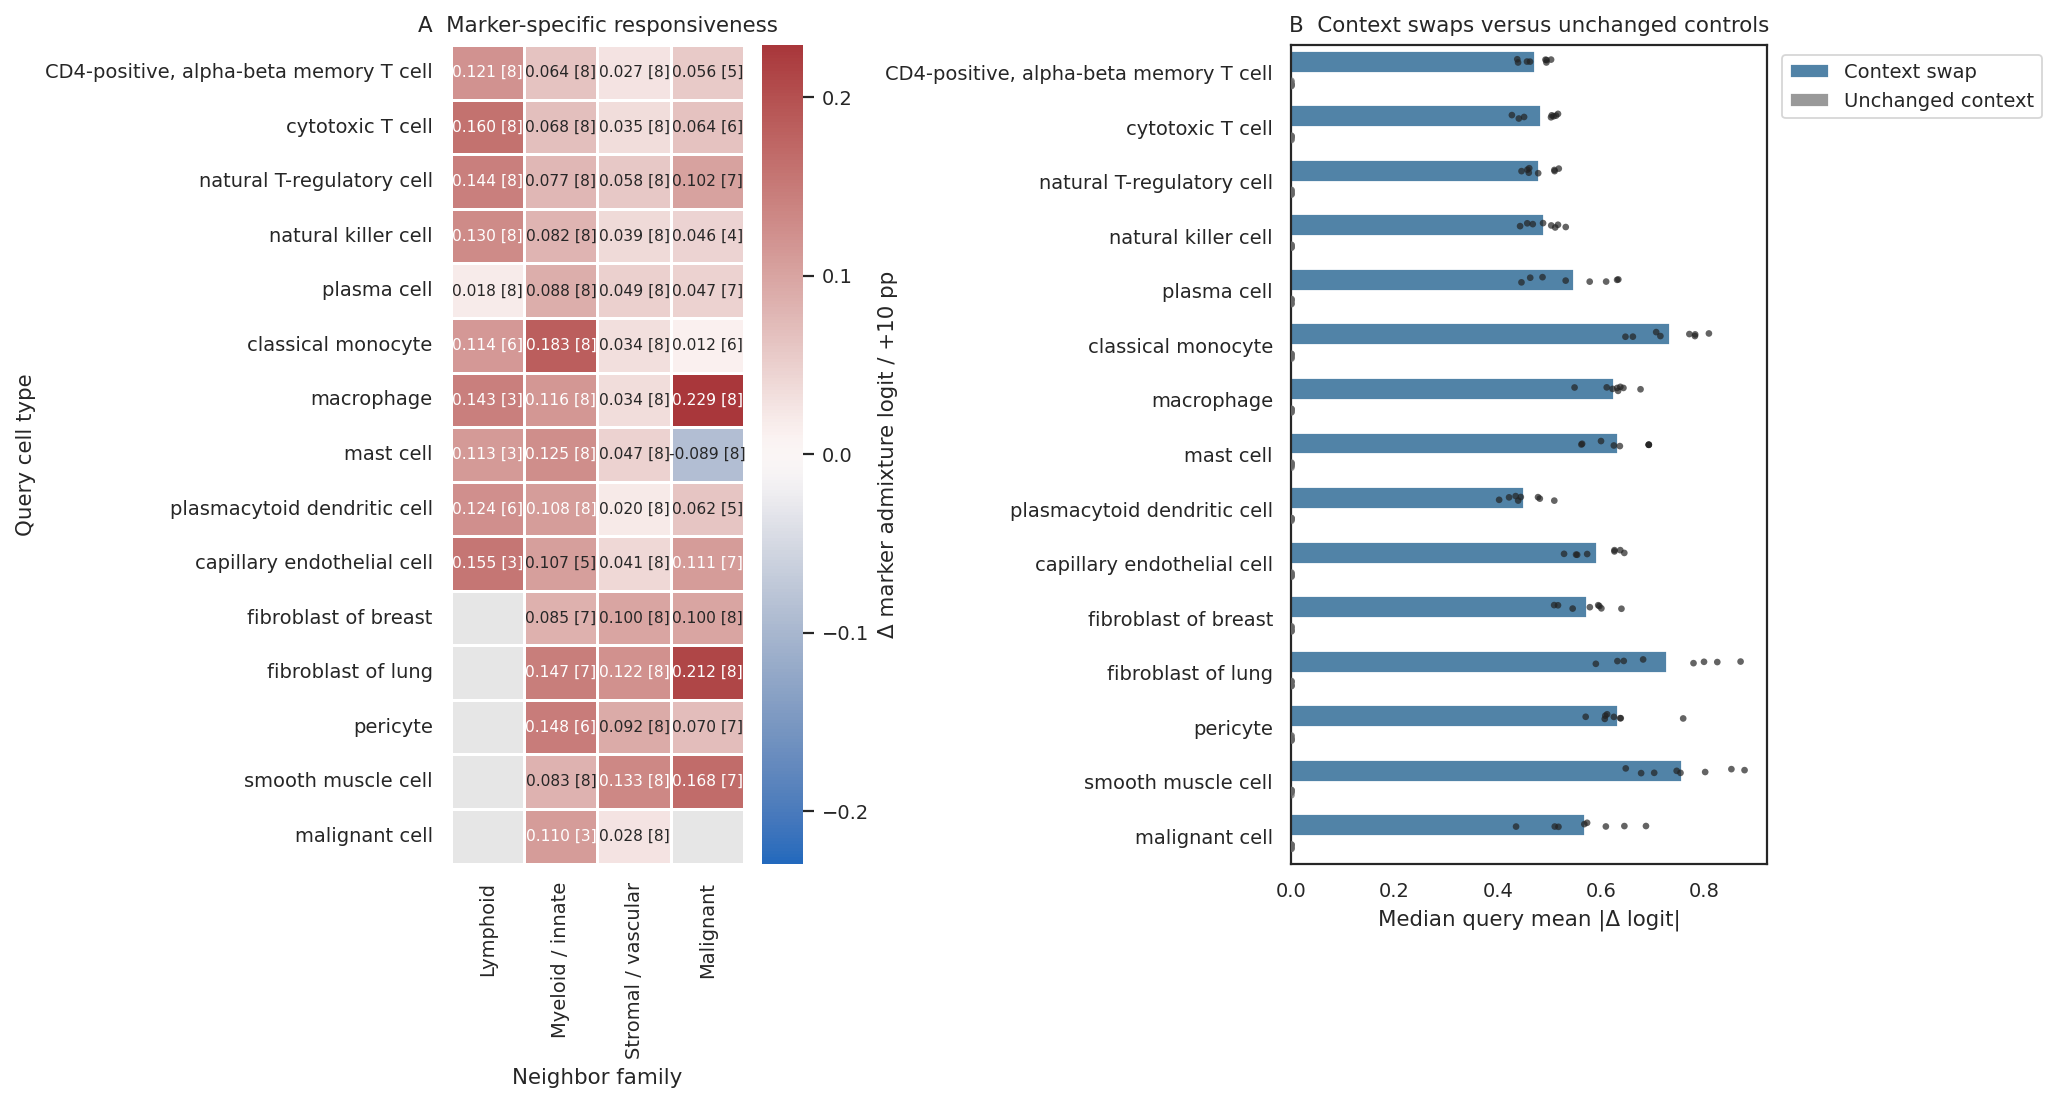

neighbor_family,Lymphoid,Myeloid / innate,Stromal / vascular,Malignant
query_cell_type,,,,
"CD4-positive, alpha-beta memory T cell",8,8,8,5
cytotoxic T cell,8,8,8,6
natural T-regulatory cell,8,8,8,7
natural killer cell,8,8,8,4
plasma cell,8,8,8,7
classical monocyte,6,8,8,6
macrophage,3,8,8,8
mast cell,3,8,8,8
plasmacytoid dendritic cell,6,8,8,5


In [3]:
supported = slopes.loc[slopes.n_queries >= MIN_SUPPORTED_QUERIES_PER_SLICE].copy()
mean_slopes = supported.groupby(['query_cell_type','neighbor_family']).median_slope.median().unstack()
n_slices = supported.groupby(['query_cell_type','neighbor_family'])['slice'].nunique().unstack(fill_value=0)
mean_slopes = mean_slopes.reindex(index=TYPE_ORDER,columns=list(FAMILIES))
n_slices = n_slices.reindex(index=TYPE_ORDER,columns=list(FAMILIES),fill_value=0).fillna(0)
mean_slopes = mean_slopes.mask(n_slices < MIN_SLICES_PER_HEATMAP_TILE)
annotation = mean_slopes.copy().astype(object)
for t in TYPE_ORDER:
    for f in FAMILIES:
        v=mean_slopes.loc[t,f]
        annotation.loc[t,f] = f'{v:.3f} [{int(n_slices.loc[t,f])}]' if pd.notna(v) else ''
fig, axes=plt.subplots(1,2,figsize=(13,7),gridspec_kw={'width_ratios':[1,1.3]})
axes[0].set_facecolor('0.9')
finite=mean_slopes.to_numpy()[np.isfinite(mean_slopes.to_numpy())]
limit=max(float(np.max(np.abs(finite))) if len(finite) else .01,.001)
sns.heatmap(mean_slopes,mask=mean_slopes.isna(),cmap='vlag',center=0,vmin=-limit,vmax=limit,
            annot=annotation,fmt='',annot_kws={'fontsize':7},linewidths=.5,ax=axes[0],
            cbar_kws={'label':'Δ marker admixture logit / +10 pp'})
axes[0].set(xlabel='Neighbor family',ylabel='Query cell type',title='A  Marker-specific responsiveness')
plot_responses=responses.assign(comparison=lambda f:f.comparison.map({'representative':'Context swap','unchanged_control':'Unchanged context'}))
sns.barplot(data=plot_responses,y='query_cell_type',x='median_absolute_delta_logit',hue='comparison',
            order=TYPE_ORDER,hue_order=['Context swap','Unchanged context'],palette=['#4385b5','#999999'],errorbar=None,ax=axes[1])
sns.stripplot(data=plot_responses,y='query_cell_type',x='median_absolute_delta_logit',hue='comparison',
              order=TYPE_ORDER,hue_order=['Context swap','Unchanged context'],dodge=True,palette=['#222222','#666666'],
              size=3,alpha=.7,legend=False,ax=axes[1])
axes[1].set(xlabel='Median query mean |Δ logit|',ylabel='',title='B  Context swaps versus unchanged controls')
axes[1].legend(title='',loc='upper left',bbox_to_anchor=(1.01,1))
fig.tight_layout()
def save_numbered(fig,stem):
    index=1
    while (FIGURES/f'{stem}_{index}.pdf').exists() or (FIGURES/f'{stem}_{index}.png').exists(): index+=1
    fig.savefig(FIGURES/f'{stem}_{index}.pdf',bbox_inches='tight')
    fig.savefig(FIGURES/f'{stem}_{index}.png',dpi=300,bbox_inches='tight')
save_numbered(fig,'all_type_responsiveness')
plt.show()
display(n_slices)


## Predefined examples

Cytotoxic T cells and breast fibroblasts, each versus malignant-family neighbor proportion. Response averages predefined malignant markers expressed in each query. Curves average within each query/composition bin, then across queries within a slice. Lines are individual slices. Sparse or unavailable marker combinations are shown explicitly, rather than replaced with the most responsive examples.

The x-axis is now **substituted minus original malignant-neighbor proportion for each query**, matching the baseline-relative y-axis. Positive x adds malignant context; negative x removes it. A zero change in malignant proportion can still change other neighbor types, so swapped-context curves need not pass through (0, 0). The unchanged-context control remains (0, 0). Within-query slopes are unchanged by subtracting each query’s constant baseline proportion.


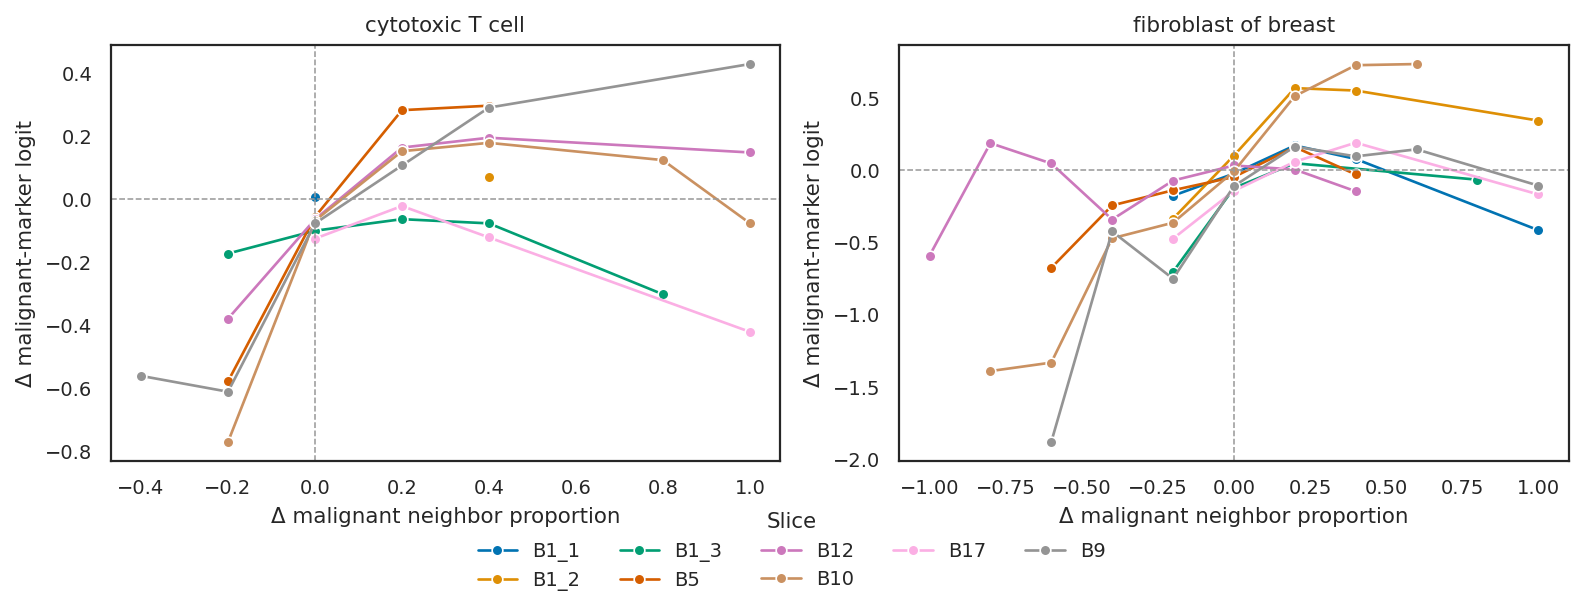

In [4]:
fig,axes=plt.subplots(1,2,figsize=(10,3.5),squeeze=False)
for ax,(query_type,family) in zip(axes.flat,EXAMPLES):
    subset=examples.loc[examples.query_cell_type.eq(query_type)&examples.neighbor_family.eq(family)].copy()
    if subset.empty:
        ax.text(.5,.5,'No expressed-marker support',ha='center',va='center',transform=ax.transAxes)
    else:
        subset['delta_proportion_bin']=np.rint(subset.delta_neighbor_proportion*5)/5
        by_query=subset.groupby(['slice','query_cell_id','delta_proportion_bin']).delta_marker_logit.mean().reset_index()
        by_slice=by_query.groupby(['slice','delta_proportion_bin']).agg(response=('delta_marker_logit','mean'),n_queries=('query_cell_id','nunique')).reset_index()
        by_slice=by_slice.loc[by_slice.n_queries>=5]
        sns.lineplot(data=by_slice,x='delta_proportion_bin',y='response',hue='slice',marker='o',estimator=None,ax=ax,
                     hue_order=SLICE_ORDER,palette=SLICE_PALETTE,legend=(ax is axes.flat[0]))
    ax.axhline(0,color='0.6',linestyle='--',linewidth=.7)
    ax.axvline(0,color='0.6',linestyle='--',linewidth=.7)
    ax.set(title=query_type,xlabel=f'Δ {family.lower()} neighbor proportion',ylabel='Δ malignant-marker logit')
handles, labels = axes.flat[0].get_legend_handles_labels()
if handles:
    axes.flat[0].get_legend().remove()
    fig.legend(handles, [SLICE_LABELS.get(label,label) for label in labels],
               title='Slice', loc='lower center', ncol=5, bbox_to_anchor=(.5,-.1),frameon=False)
fig.tight_layout()
save_numbered(fig,'predefined_examples_delta_context')
plt.show()


## Reproducibility and interpretation

`design.json` records source files, checkpoint, sampling seed, eligibility rules, and controls. `contexts/*_coverage.csv` records every intended query type, including missing types. Per-query response/slopes and per-slice summaries are retained alongside marker coverage and status tables.

The design has one sampling repeat. This panel demonstrates context sensitivity and checks specificity; it does not establish correction accuracy, physical contamination, or biological identity changes. Use neighbor-token ablations as complementary evidence. Different-type neighbors reflect model training and exclude the query's own exact type, so neighborhood-family support differs among query types. Inference time and GPU memory must be measured from the pilot before making runtime claims.


## Gene-ranking responsiveness

Ranks use the existing **untransformed probabilities**, restricted to the same expressed genes within each query. Higher ranks mean higher predicted contamination. Probability and logit ranks agree except where logit clipping creates ties, so raw probabilities avoid that clipping artifact.

For each context, compare against the same query's original neighborhood: **rank distance = 1 − Spearman ρ** (0 = unchanged; up to 2 for reversed rankings), and top-10%/20% removal-priority overlap. Queries need ≥10 expressed genes. Top sets contain at least three genes; ties at the cutoff receive fractional membership, with overlap defined as sum of the minimum memberships divided by k. Identical tied rankings therefore have overlap 1. Constant-rank vectors have undefined Spearman and are reported rather than assigned 0 distance.

Summaries first average over contexts within query, then take medians within slice. Identical-context controls should have rank distance 0 and overlap 1. Overlap quantifies gene prioritization, not counts removed or biological accuracy.


{'n_slices': 8, 'n_ranked_queries': 3587, 'rank_source': 'raw probabilities, without clipping or logit', 'minimum_expressed_genes': 10, 'top_k_minimum': 3, 'ties': 'average ranks; fractional top-k memberships; overlap=sum(min(weights))/k'}


comparison         status
representative     ok        3587
unchanged_control  ok        3587
Name: n_queries, dtype: int64

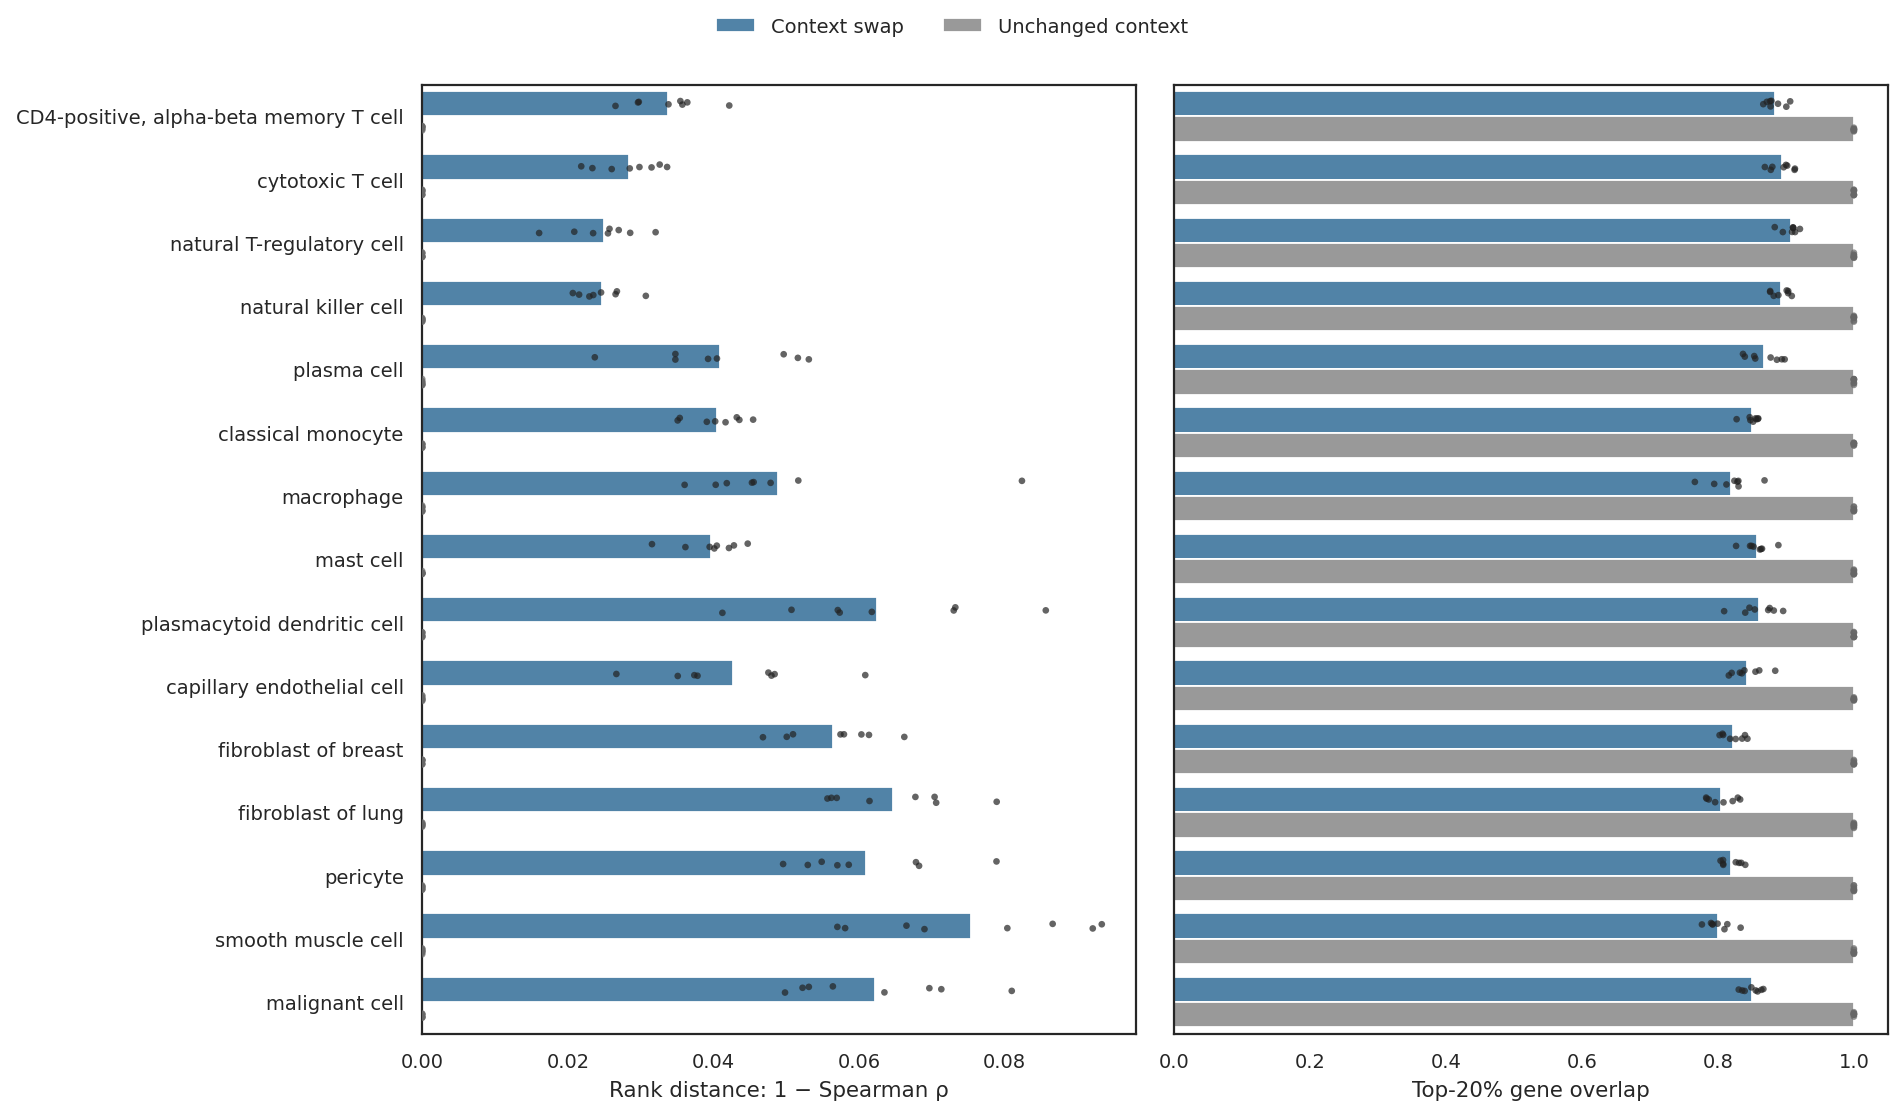

,median_rank_distance,median_top10_overlap,median_top20_overlap
query_cell_type,,,
"CD4-positive, alpha-beta memory T cell",0.034640,0.840278,0.877967
capillary endothelial cell,0.042678,0.756667,0.837037
classical monocyte,0.040950,0.803333,0.853541
cytotoxic T cell,0.029171,0.853056,0.898333
fibroblast of breast,0.057684,0.757589,0.821934
fibroblast of lung,0.064583,0.727976,0.801968
macrophage,0.045404,0.776984,0.826369
malignant cell,0.059941,0.823333,0.852350
mast cell,0.040289,0.813889,0.857024


In [5]:
RANK_SUMMARY = RUN / 'summaries_ranks'
if not (RANK_SUMMARY/'complete.json').exists():
    raise FileNotFoundError(f'Ranking summaries not complete: {RANK_SUMMARY}')
rank_metadata = json.loads((RANK_SUMMARY/'complete.json').read_text())
print(rank_metadata)
rank_slices = pd.read_csv(RANK_SUMMARY/'slice_rank_changes.csv')
rank_markers = pd.read_csv(RANK_SUMMARY/'slice_marker_rank_slopes.csv')
rank_examples = pd.read_csv(DELTA_CONTEXT/'rank_examples.csv.gz')
rank_query_status = pd.read_csv(RANK_SUMMARY/'query_rank_changes.csv.gz')
display(rank_query_status.groupby(['comparison','status']).size().rename('n_queries'))
rank_plot=rank_slices.assign(comparison=lambda f:f.comparison.map({'representative':'Context swap','unchanged_control':'Unchanged context'}))
fig,axes=plt.subplots(1,2,figsize=(12,7),sharey=True)
for ax,metric,label in zip(axes,['median_rank_distance','median_top20_overlap'],
                           ['Rank distance: 1 − Spearman ρ','Top-20% gene overlap']):
    sns.barplot(data=rank_plot,y='query_cell_type',x=metric,hue='comparison',order=TYPE_ORDER,
                hue_order=['Context swap','Unchanged context'],palette=['#4385b5','#999999'],errorbar=None,ax=ax)
    sns.stripplot(data=rank_plot,y='query_cell_type',x=metric,hue='comparison',order=TYPE_ORDER,
                  hue_order=['Context swap','Unchanged context'],palette=['#222222','#666666'],
                  dodge=True,alpha=.7,size=3,legend=False,ax=ax)
    ax.set(xlabel=label,ylabel='')
    ax.legend_.remove()
handles,labels=axes[0].get_legend_handles_labels()
fig.legend(handles,labels,loc='upper center',ncol=2,frameon=False)
fig.tight_layout(rect=[0,0,1,.95])
save_numbered(fig,'ranking_responsiveness')
plt.show()
display(rank_slices.loc[rank_slices.comparison.eq('representative')].groupby('query_cell_type')[
    ['median_rank_distance','median_top10_overlap','median_top20_overlap']].median())


## Do neighboring-family markers rise in rank?

Slopes compare each query's mean marker-rank percentile across its substituted contexts. Percentile is (average rank − 1)/(number of expressed genes − 1), so positive slopes mean markers move toward the genes prioritized for removal. Only expressed predefined markers enter each query's comparison. The same ≥10-query/≥3-slice support rule is used as above. These marginal composition associations do not isolate the effect of replacing a single neighbor token.


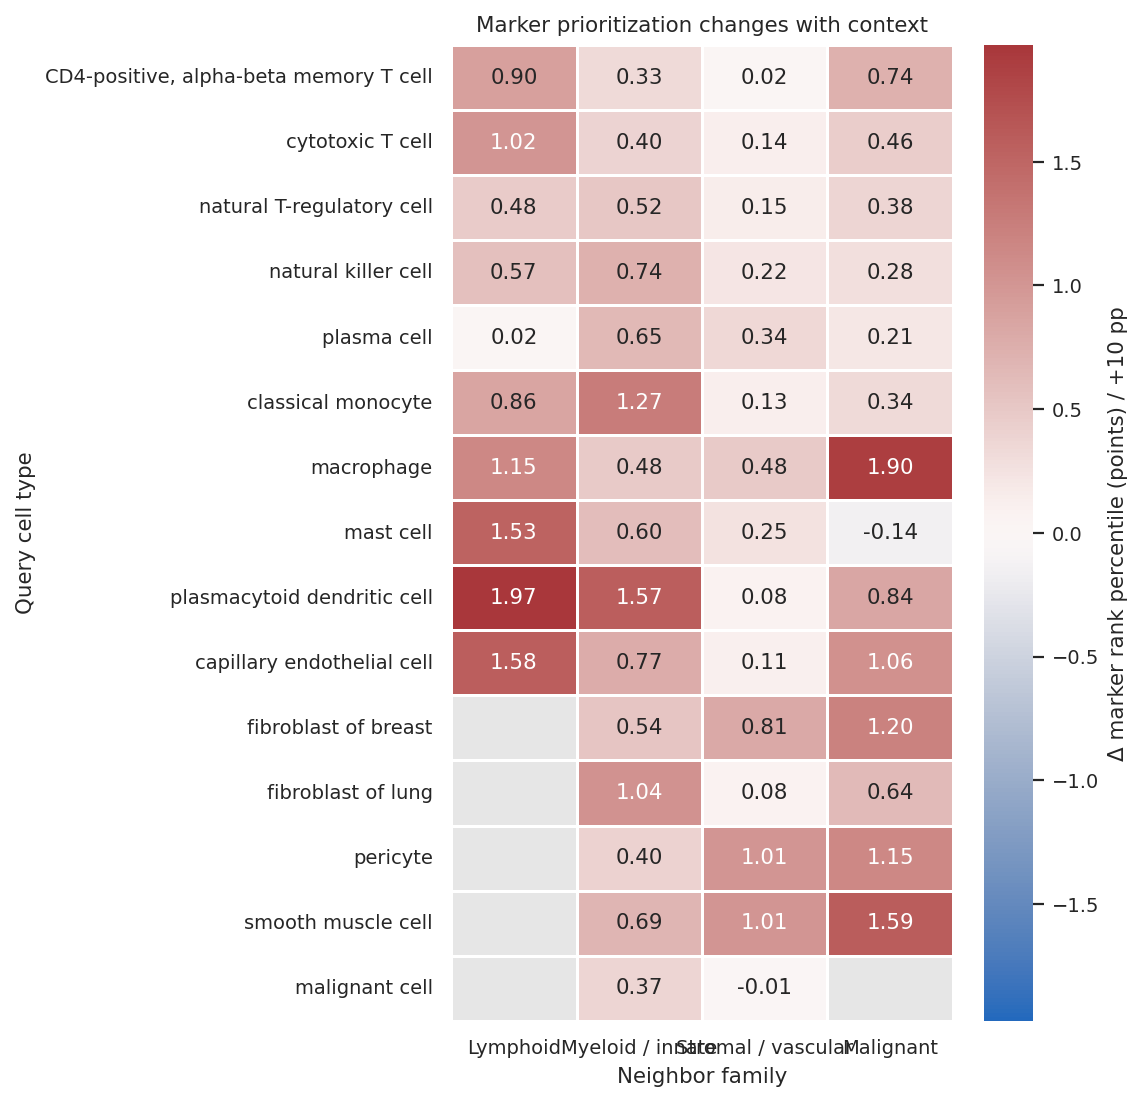

neighbor_family,Lymphoid,Myeloid / innate,Stromal / vascular,Malignant
query_cell_type,,,,
"CD4-positive, alpha-beta memory T cell",8,8,8,5
cytotoxic T cell,8,8,8,6
natural T-regulatory cell,8,8,8,7
natural killer cell,8,8,8,4
plasma cell,8,8,8,7
classical monocyte,6,8,8,6
macrophage,3,8,8,8
mast cell,3,8,8,8
plasmacytoid dendritic cell,6,8,8,5


,n_slices,median_rank_slope,n_positive_slices,n_negative_slices
query_cell_type,,,,
"CD4-positive, alpha-beta memory T cell",5,0.007361,5,0
capillary endothelial cell,7,0.010597,6,1
classical monocyte,6,0.003360,5,1
cytotoxic T cell,6,0.004604,5,1
fibroblast of breast,8,0.012020,8,0
fibroblast of lung,8,0.006399,7,1
macrophage,8,0.019016,8,0
mast cell,8,-0.001441,2,6
natural T-regulatory cell,7,0.003841,7,0


In [6]:
supported_ranks=rank_markers.loc[rank_markers.n_queries>=MIN_SUPPORTED_QUERIES_PER_SLICE]
rank_heatmap=supported_ranks.groupby(['query_cell_type','neighbor_family']).median_rank_slope.median().unstack()
rank_support=supported_ranks.groupby(['query_cell_type','neighbor_family'])['slice'].nunique().unstack(fill_value=0)
rank_heatmap=rank_heatmap.reindex(index=TYPE_ORDER,columns=list(FAMILIES))
rank_support=rank_support.reindex(index=TYPE_ORDER,columns=list(FAMILIES),fill_value=0).fillna(0)
rank_heatmap=rank_heatmap.mask(rank_support<MIN_SLICES_PER_HEATMAP_TILE)
fig,ax=plt.subplots(figsize=(7,7));ax.set_facecolor('0.9')
finite=rank_heatmap.to_numpy()[np.isfinite(rank_heatmap.to_numpy())]
limit=max(float(np.max(np.abs(finite))) if len(finite) else .01,.001)
sns.heatmap(100*rank_heatmap,mask=rank_heatmap.isna(),cmap='vlag',center=0,vmin=-100*limit,vmax=100*limit,
            annot=True,fmt='.2f',linewidths=.5,ax=ax,cbar_kws={'label':'Δ marker rank percentile (points) / +10 pp'})
ax.set(xlabel='Neighbor family',ylabel='Query cell type',title='Marker prioritization changes with context')
fig.tight_layout();save_numbered(fig,'marker_rank_responsiveness');plt.show()
display(rank_support)
malignant_rank_summary = supported_ranks.loc[supported_ranks.neighbor_family.eq('Malignant')].groupby('query_cell_type').agg(
    n_slices=('slice','nunique'),median_rank_slope=('median_rank_slope','median'),
    n_positive_slices=('median_rank_slope',lambda x:int((x>0).sum())),
    n_negative_slices=('median_rank_slope',lambda x:int((x<0).sum())))
display(malignant_rank_summary)


## Predefined malignant-marker rank examples

The same cytotoxic-T and breast-fibroblast examples are shown as baseline-relative rank-percentile changes. Positive values indicate increased removal priority. The slice-level slopes below are computed within each query before aggregation; the curves are descriptive binned averages and may include different queries in different bins.

The x-axis also uses **Δ malignant-neighbor proportion relative to the same query’s original neighborhood**. Original proportions are joined by slice, query ID, and family; the y-axis remains baseline-relative rank change.


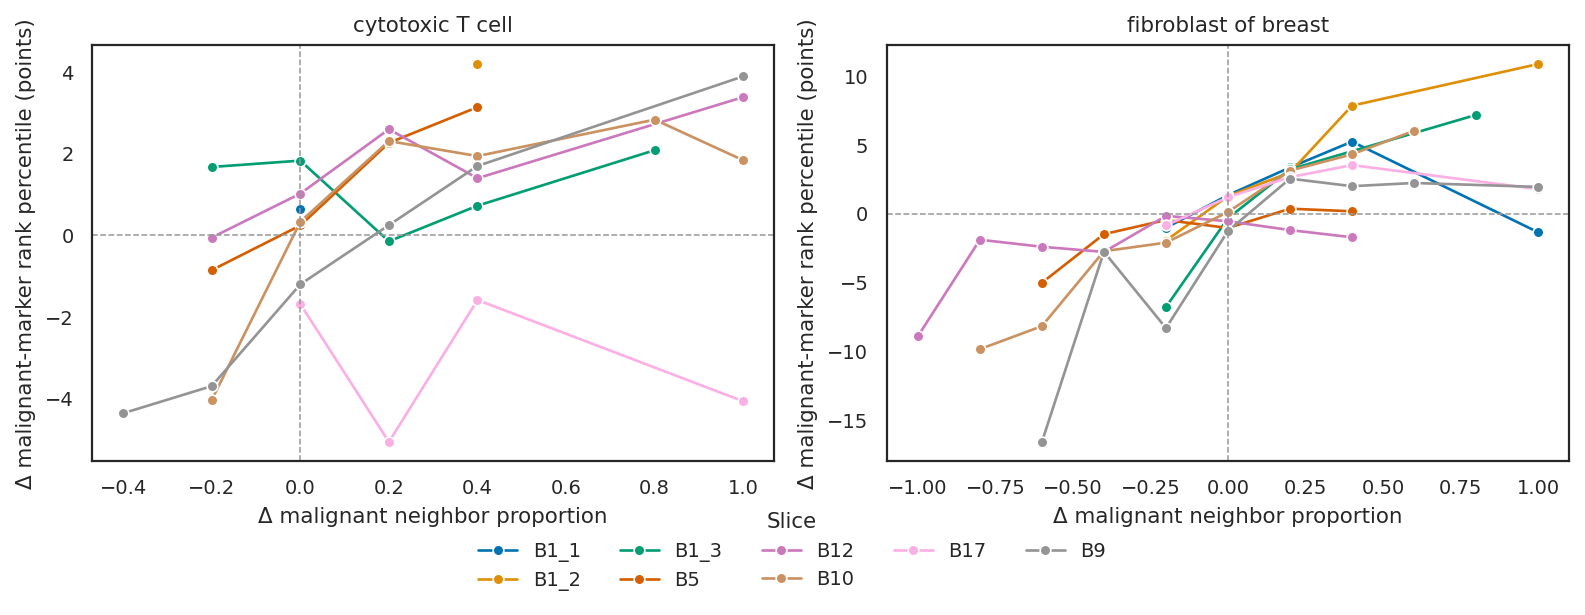

,slice,query_cell_type,neighbor_family,median_rank_slope,n_queries
13,GSM9509156_breast_breast_B17_B17_rctd_annotated,cytotoxic T cell,Malignant,-0.001480,10
17,GSM9509156_breast_breast_B17_B17_rctd_annotated,fibroblast of breast,Malignant,0.006204,14
72,GSM9509162_breast_breast_B12_B12_rctd_annotated,cytotoxic T cell,Malignant,0.004671,15
76,GSM9509162_breast_breast_B12_B12_rctd_annotated,fibroblast of breast,Malignant,0.008665,18
131,GSM9509164_breast_breast_B10_B10_rctd_annotated,cytotoxic T cell,Malignant,0.003611,19
135,GSM9509164_breast_breast_B10_B10_rctd_annotated,fibroblast of breast,Malignant,0.020617,21
190,GSM9509166_breast_breast_B9_B9_rctd_annotated,cytotoxic T cell,Malignant,0.005273,19
194,GSM9509166_breast_breast_B9_B9_rctd_annotated,fibroblast of breast,Malignant,0.018879,17
249,GSM9509171_breast_breast_B5_B5_rctd_annotated,cytotoxic T cell,Malignant,0.006166,11
253,GSM9509171_breast_breast_B5_B5_rctd_annotated,fibroblast of breast,Malignant,0.011632,14


In [7]:
fig,axes=plt.subplots(1,2,figsize=(10,3.5),squeeze=False)
for ax,(query_type,family) in zip(axes.flat,EXAMPLES):
    subset=rank_examples.loc[rank_examples.query_cell_type.eq(query_type)&rank_examples.neighbor_family.eq(family)].copy()
    if subset.empty:
        ax.text(.5,.5,'No expressed-marker support',ha='center',va='center',transform=ax.transAxes)
    else:
        subset['delta_proportion_bin']=np.rint(subset.delta_neighbor_proportion*5)/5
        by_query=subset.groupby(['slice','query_cell_id','delta_proportion_bin']).delta_marker_rank_percentile.mean().reset_index()
        by_slice=by_query.groupby(['slice','delta_proportion_bin']).agg(response=('delta_marker_rank_percentile','mean'),n_queries=('query_cell_id','nunique')).reset_index()
        by_slice=by_slice.loc[by_slice.n_queries>=5].copy();by_slice['response']*=100
        sns.lineplot(data=by_slice,x='delta_proportion_bin',y='response',hue='slice',marker='o',estimator=None,ax=ax,
                     hue_order=SLICE_ORDER,palette=SLICE_PALETTE,legend=(ax is axes.flat[0]))
    ax.axhline(0,color='0.6',linestyle='--',linewidth=.7)
    ax.axvline(0,color='0.6',linestyle='--',linewidth=.7)
    ax.set(title=query_type,xlabel=f'Δ {family.lower()} neighbor proportion',ylabel='Δ malignant-marker rank percentile (points)')
handles,labels=axes.flat[0].get_legend_handles_labels()
if handles:
    axes.flat[0].get_legend().remove()
    fig.legend(handles,[SLICE_LABELS.get(label,label) for label in labels],title='Slice',loc='lower center',ncol=5,bbox_to_anchor=(.5,-.1),frameon=False)
fig.tight_layout();save_numbered(fig,'malignant_marker_rank_examples_delta_context');plt.show()
display(supported_ranks.loc[supported_ranks.query_cell_type.isin([e[0] for e in EXAMPLES]) &
                           supported_ranks.neighbor_family.eq('Malignant')])


## How much malignant-neighbor variation is present naturally?

These distributions use **every eligible cell** of the tested types in the selected slices, rather than only the 30 sampled query cells or the deliberately diverse swapped contexts. Query eligibility matches the experiment: ≥10 counts, ≥5 expressed genes, finite coordinates and labels, and five eligible neighbors. Neighbors have >10 counts. Summaries require five neighbors under both definitions so the two views compare the same query cells.

- **Model context:** the five nearest eligible neighbors excluding the query's exact annotated type, matching the input used in the experiment.
- **Physical context:** the five nearest eligible neighbors allowing the query's own type, describing local spatial context without that type exclusion.

Malignant queries have zero malignant proportion in the model context **by construction**. This must not be interpreted as a lack of malignant clustering in the tissue; the physical-context panel shows their natural local tumor context. Both definitions allow proportions 0, 0.2, …, 1. Slices are displayed separately, with pooled cell-weighted and slice-balanced tables also provided.


,cell_type,definition,n_cells,n_slices,pooled_mean,pooled_sd,pooled_fraction_zero,median_slice_sd,median_slice_iqr,n_slices_with_context_variation
0,"CD4-positive, alpha-beta memory T cell",model_context,14783,8,0.084678,0.182439,0.764459,0.174864,0.10,8
1,"CD4-positive, alpha-beta memory T cell",physical_context,14783,8,0.077535,0.175502,0.782791,0.166547,0.10,8
2,capillary endothelial cell,model_context,45576,8,0.219379,0.287682,0.526527,0.277995,0.40,8
3,capillary endothelial cell,physical_context,45576,8,0.150974,0.230517,0.612647,0.210060,0.20,8
4,classical monocyte,model_context,54629,8,0.186890,0.270229,0.579802,0.222472,0.30,8
5,classical monocyte,physical_context,54629,8,0.158842,0.246387,0.617840,0.207505,0.20,8
6,cytotoxic T cell,model_context,38698,8,0.134002,0.235309,0.676211,0.195784,0.10,8
7,cytotoxic T cell,physical_context,38698,8,0.113747,0.215383,0.710838,0.181668,0.10,8
8,fibroblast of breast,model_context,48726,8,0.219140,0.292882,0.540184,0.271492,0.30,8
9,fibroblast of breast,physical_context,48726,8,0.185462,0.262485,0.574929,0.261906,0.30,8


,slice,cell_type,definition,n_cells,mean,sd,iqr,q10,q90,fraction_zero,n_distinct_proportions,tested,sufficient_family_variation
0,GSM9509172_breast_breast_B1_B1_1_rctd_annotated,"CD4-positive, alpha-beta memory T cell",model_context,1975,0.053570,0.148396,0.0,0.0,0.2,0.845063,6,True,True
1,GSM9509172_breast_breast_B1_B1_1_rctd_annotated,"CD4-positive, alpha-beta memory T cell",physical_context,1975,0.049823,0.143408,0.0,0.0,0.2,0.855696,6,True,True
2,GSM9509172_breast_breast_B1_B1_1_rctd_annotated,cytotoxic T cell,model_context,6203,0.074158,0.170521,0.0,0.0,0.2,0.790263,6,True,True
3,GSM9509172_breast_breast_B1_B1_1_rctd_annotated,cytotoxic T cell,physical_context,6203,0.063195,0.157906,0.0,0.0,0.2,0.817185,6,True,True
4,GSM9509172_breast_breast_B1_B1_1_rctd_annotated,natural T-regulatory cell,model_context,3678,0.156552,0.260075,0.2,0.0,0.6,0.656063,6,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...
235,GSM9509166_breast_breast_B9_B9_rctd_annotated,pericyte,physical_context,1222,0.232897,0.288000,0.4,0.0,0.6,0.504092,6,True,True
236,GSM9509166_breast_breast_B9_B9_rctd_annotated,smooth muscle cell,model_context,3508,0.318472,0.317794,0.6,0.0,0.8,0.379133,6,True,True
237,GSM9509166_breast_breast_B9_B9_rctd_annotated,smooth muscle cell,physical_context,3508,0.285747,0.301860,0.6,0.0,0.8,0.405359,6,True,True
238,GSM9509166_breast_breast_B9_B9_rctd_annotated,malignant cell,model_context,45274,0.000000,0.000000,0.0,0.0,0.0,1.000000,1,True,False


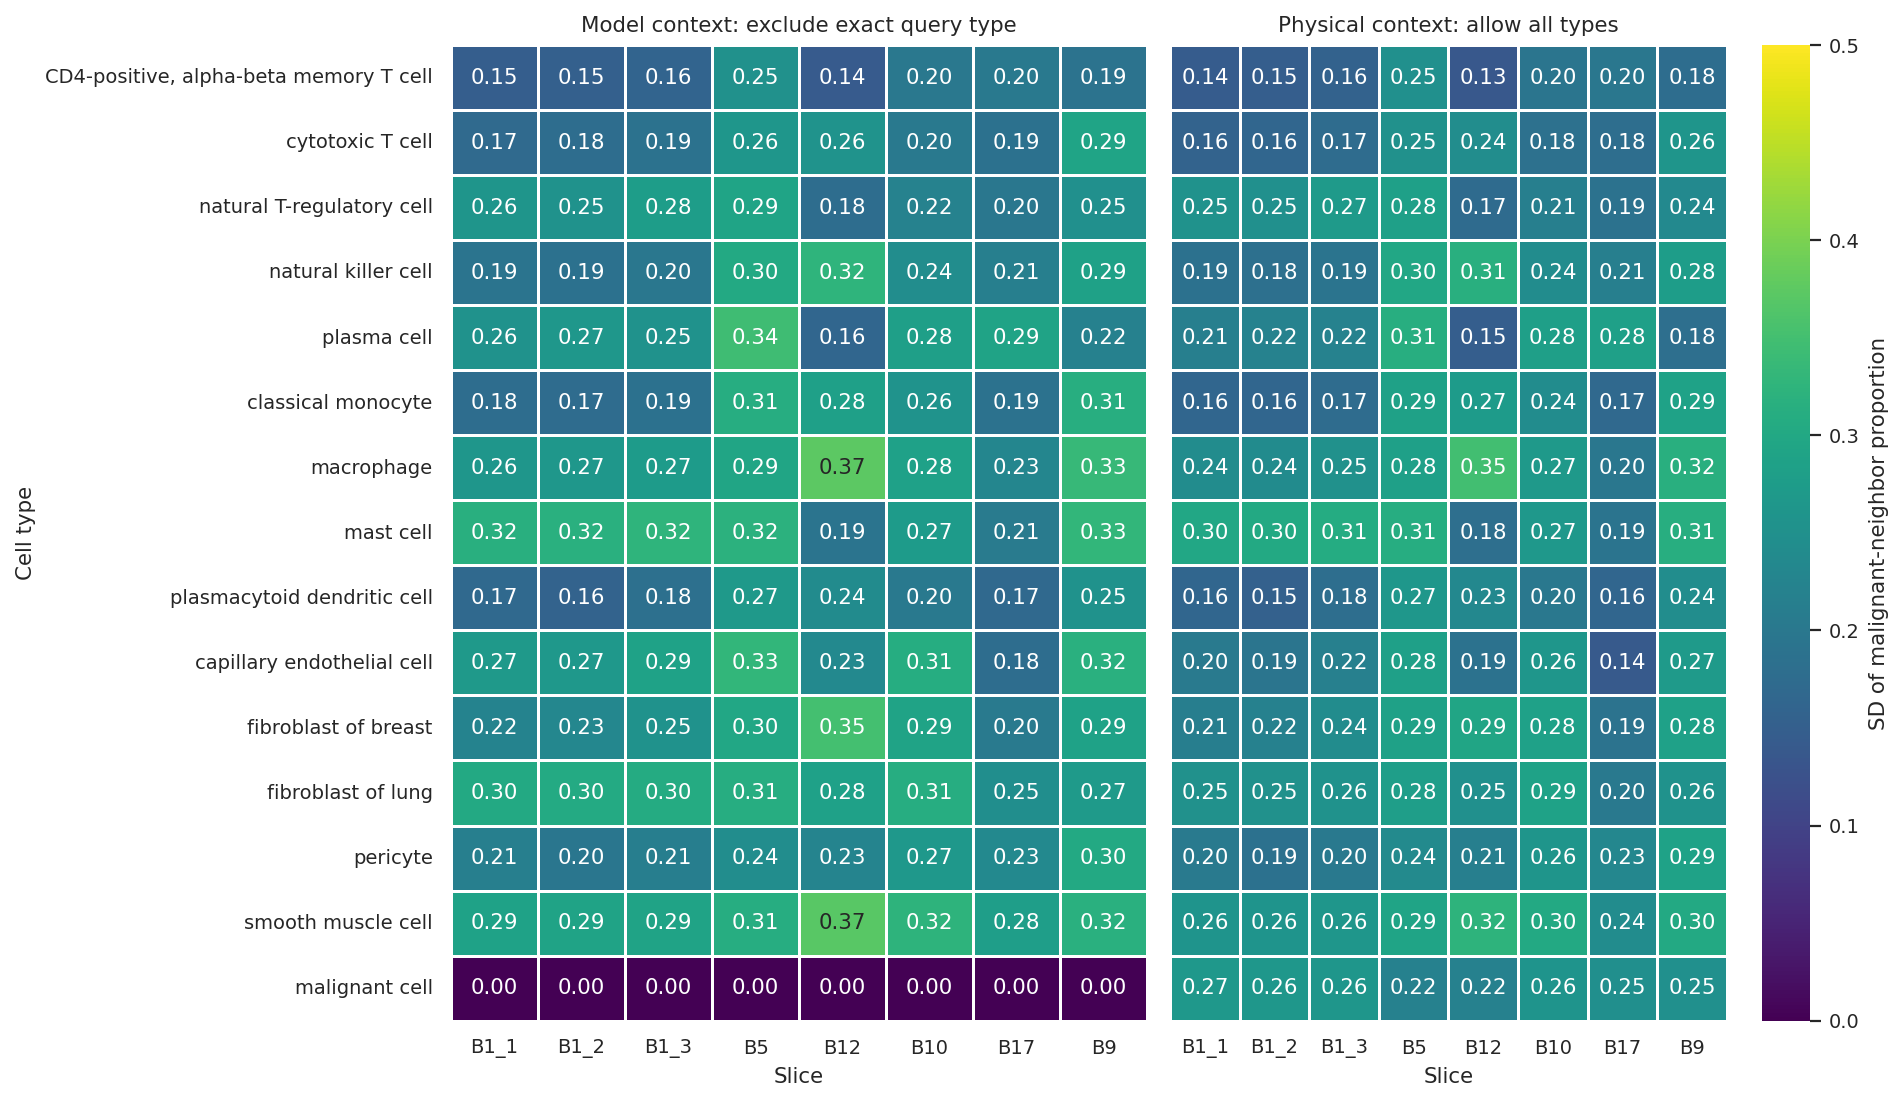

In [8]:
VARIATION = RUN/'context_variability'
if not (VARIATION/'complete.json').exists():
    raise FileNotFoundError(f'Population context-variation analysis incomplete: {VARIATION}')
context_variation = pd.read_csv(VARIATION/'slice_context_variability.csv')
context_distribution = pd.read_csv(VARIATION/'slice_distributions.csv')
context_pooled = pd.read_csv(VARIATION/'pooled_context_variability.csv')
display(context_pooled)
display(context_variation[['slice','cell_type','definition','n_cells','mean','sd','iqr',
                          'q10','q90','fraction_zero','n_distinct_proportions','tested','sufficient_family_variation']])
fig,axes=plt.subplots(1,2,figsize=(12,7),sharey=True)
for ax,definition,title in zip(axes,['model_context','physical_context'],
                              ['Model context: exclude exact query type','Physical context: allow all types']):
    heat=context_variation.loc[context_variation.definition.eq(definition)].pivot(index='cell_type',columns='slice',values='sd')
    heat=heat.reindex(index=TYPE_ORDER,columns=SLICE_ORDER).rename(columns=SLICE_LABELS)
    sns.heatmap(heat,cmap='viridis',vmin=0,vmax=.5,annot=True,fmt='.2f',linewidths=.5,ax=ax,
                cbar=(definition=='physical_context'),cbar_kws={'label':'SD of malignant-neighbor proportion'})
    ax.set(title=title,xlabel='Slice',ylabel='Cell type' if definition=='model_context' else '')
fig.tight_layout();save_numbered(fig,'natural_malignant_context_sd');plt.show()


### Distribution of malignant-neighbor proportions

Stacked bars average the per-slice proportions equally across slices containing that cell type. Thus, a large slice does not dominate the distribution. The pooled table above separately reports cell-weighted results. Zero cells and absent types remain unavailable rather than being assigned zero variance.


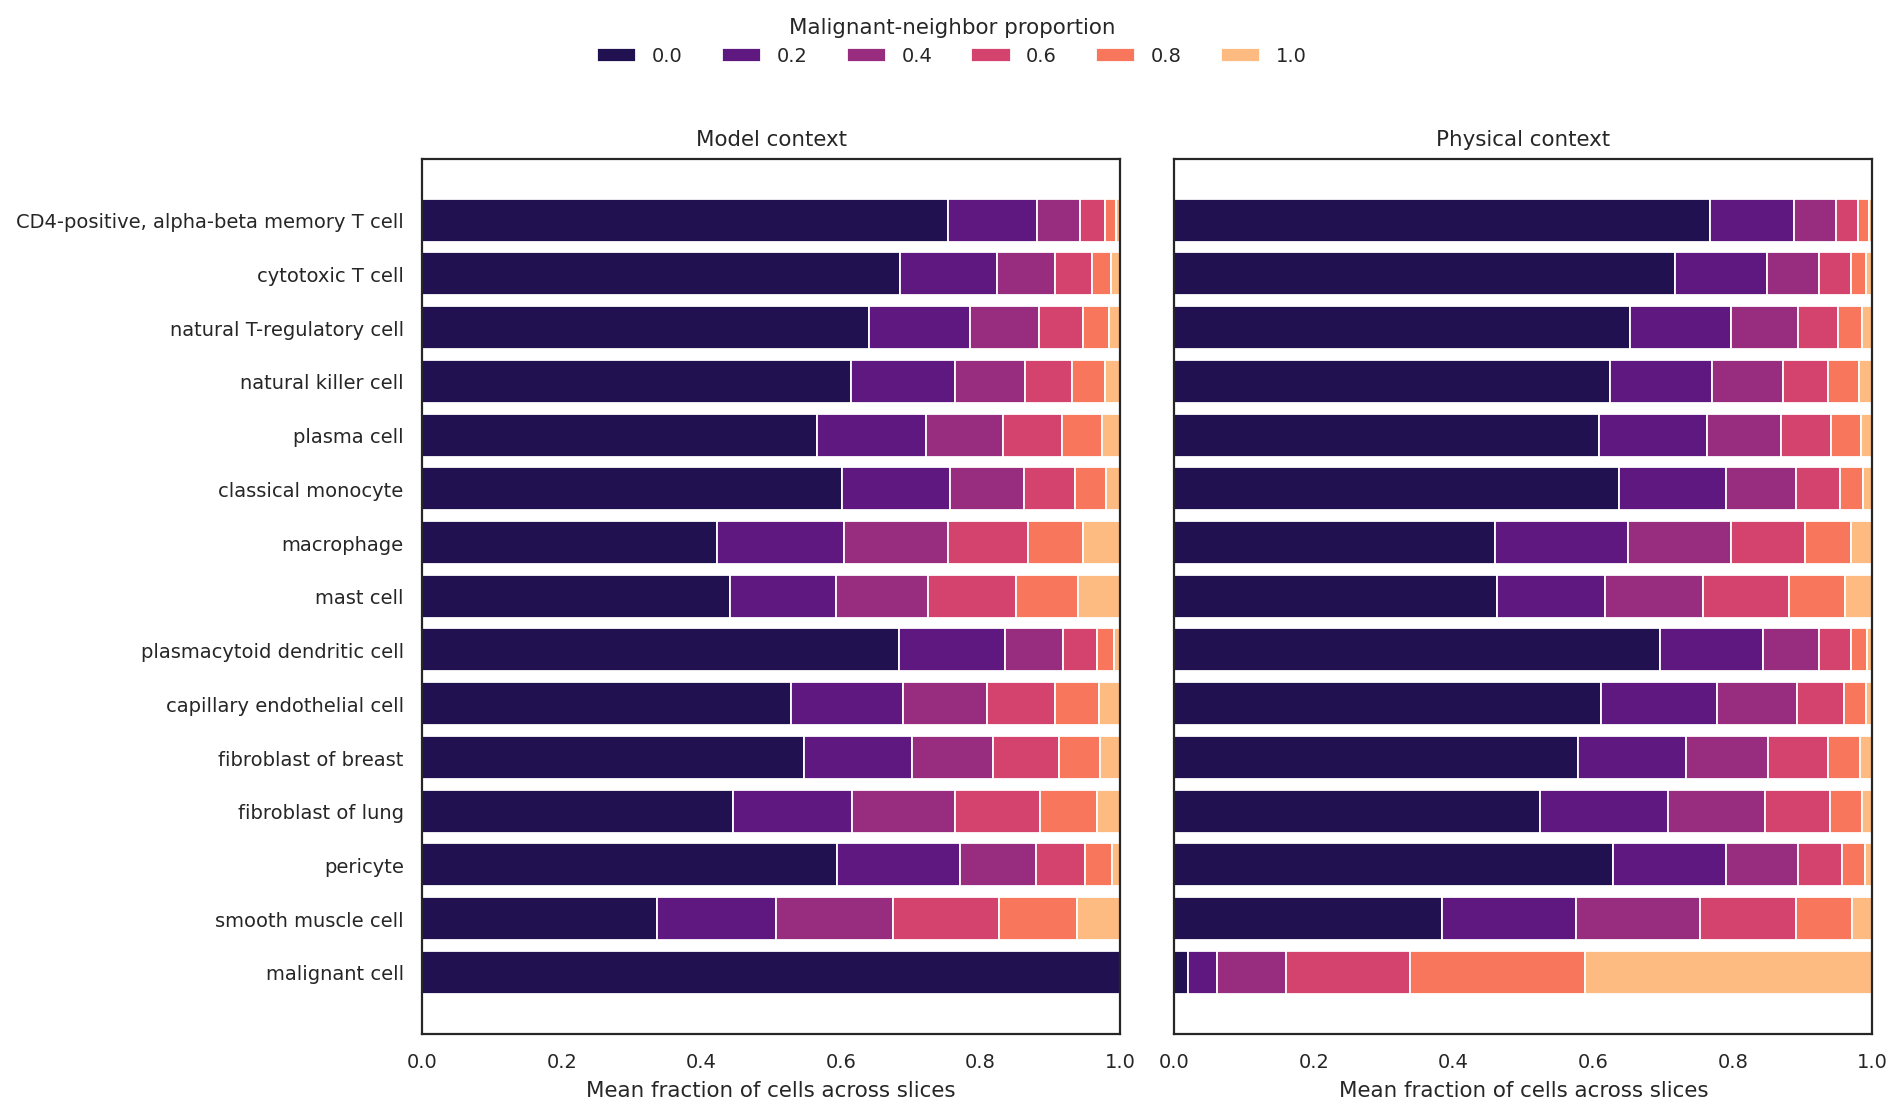

In [9]:
balanced = pd.read_csv(VARIATION/'slice_balanced_distribution.csv')
fig,axes=plt.subplots(1,2,figsize=(12,7),sharey=True)
levels=[i/5 for i in range(6)]
level_colors=sns.color_palette('magma',6)
for ax,definition,title in zip(axes,['model_context','physical_context'],['Model context','Physical context']):
    table=balanced.loc[balanced.definition.eq(definition)].pivot(index='cell_type',columns='malignant_neighbor_proportion',values='mean_slice_fraction')
    table=table.reindex(index=TYPE_ORDER,columns=levels)
    left=np.zeros(len(TYPE_ORDER))
    for level,color in zip(levels,level_colors):
        values=table[level].fillna(0).to_numpy()
        ax.barh(np.arange(len(TYPE_ORDER)),values,left=left,color=color,label=f'{level:.1f}')
        left+=values
    ax.set_yticks(np.arange(len(TYPE_ORDER)),TYPE_ORDER)
    ax.set(xlim=(0,1),xlabel='Mean fraction of cells across slices',title=title)

axes[0].invert_yaxis()
handles,labels=axes[0].get_legend_handles_labels()
fig.legend(handles,labels,title='Malignant-neighbor proportion',loc='upper center',ncol=6,frameon=False)
fig.tight_layout(rect=[0,0,1,.91]);save_numbered(fig,'natural_malignant_context_distribution');plt.show()


## Distance to the nearest malignant cell

Distances are **2D Euclidean centroid distances in micrometers**, using `x_centroid`/`y_centroid` and every finite-coordinate cell annotated `malignant cell` in the same slice. This measures distance to an annotated cell centroid, not a tumor boundary. No counts filter is applied to malignant reference cells.

Two complementary comparisons are shown:

1. **Original contexts:** the query's actual distance versus its original-context malignant-marker logit and removal-priority rank. These are observational comparisons across different cells; expression can differ.
2. **Swapped contexts:** the distance at the context-donor location versus each fixed query's change in marker scores/ranks. The query never moves. The default x-axis is donor distance minus original query distance, consistent with the previous delta-proportion plots. More-negative x means the donor is closer to malignant cells; more-positive x means farther away. Set `DISTANCE_X_MODE = 'absolute'` for raw donor distance.

Malignant queries have zero distance because self is included; they are omitted from proximity correlations/plots and retained in the exported data. Original-context correlations require ≥10 supported queries and variable distances/scores; no significance tests assume cells are biological replicates.


In [10]:
DISTANCE_SUMMARY = RUN/'summaries_distance'
DISTANCE_X_MODE = 'delta'  # 'delta' or 'absolute'
DISTANCE_BIN_WIDTH_UM = 25
MIN_QUERIES_PER_DISTANCE_BIN = 5
if DISTANCE_X_MODE not in {'delta','absolute'}:
    raise ValueError("DISTANCE_X_MODE must be 'delta' or 'absolute'")
if not (DISTANCE_SUMMARY/'complete.json').exists():
    raise FileNotFoundError(f'Distance summaries not available: {DISTANCE_SUMMARY}')
print(json.loads((DISTANCE_SUMMARY/'complete.json').read_text()))
distance_original = pd.read_csv(DISTANCE_SUMMARY/'query_original_distance_scores.csv')
distance_contexts = pd.read_csv(DISTANCE_SUMMARY/'example_distance_responses.csv.gz')
distance_correlations = pd.read_csv(DISTANCE_SUMMARY/'original_distance_correlations.csv')
distance_context_correlations = pd.read_csv(DISTANCE_SUMMARY/'query_context_distance_correlations.csv')
display(pd.read_csv(DISTANCE_SUMMARY/'distance_audit.csv'))


{'n_slices': 8, 'n_queries': 3600, 'units': 'micrometers', 'distance': '2D Euclidean centroid distance to nearest annotated malignant cell in same slice; all finite-coordinate malignant cells, no source-count filter', 'malignant_queries': 'Self included: distance zero; omitted from proximity-response plots', 'context_donor_distance': 'Distance at the donor location, not physical relocation of the query; raw distance and delta relative to original query both exported'}


,slice,n_annotated_malignant_cells,n_finite_coordinate_cells,n_queries
0,GSM9509172_breast_breast_B1_B1_1_rctd_annotated,40931,124525,450
1,GSM9509173_breast_breast_B1_B1_2_rctd_annotated,46977,141262,450
2,GSM9509174_breast_breast_B1_B1_3_rctd_annotated,37022,108069,450
3,GSM9509171_breast_breast_B5_B5_rctd_annotated,109305,185547,450
4,GSM9509162_breast_breast_B12_B12_rctd_annotated,87591,151364,450
5,GSM9509164_breast_breast_B10_B10_rctd_annotated,30217,66079,450
6,GSM9509156_breast_breast_B17_B17_rctd_annotated,25574,68181,450
7,GSM9509166_breast_breast_B9_B9_rctd_annotated,45274,98081,450


### Original-context proximity associations across cell types

Each tile is a within-slice Spearman correlation across queried cells of the same annotated type. Positive values mean larger scores/ranks farther from malignant cells; negative values mean larger scores/ranks nearer malignant cells. Gray tiles have insufficient support. The two metrics use the expressed epithelial/malignant-marker set defined above. These markers are not uniquely malignant.


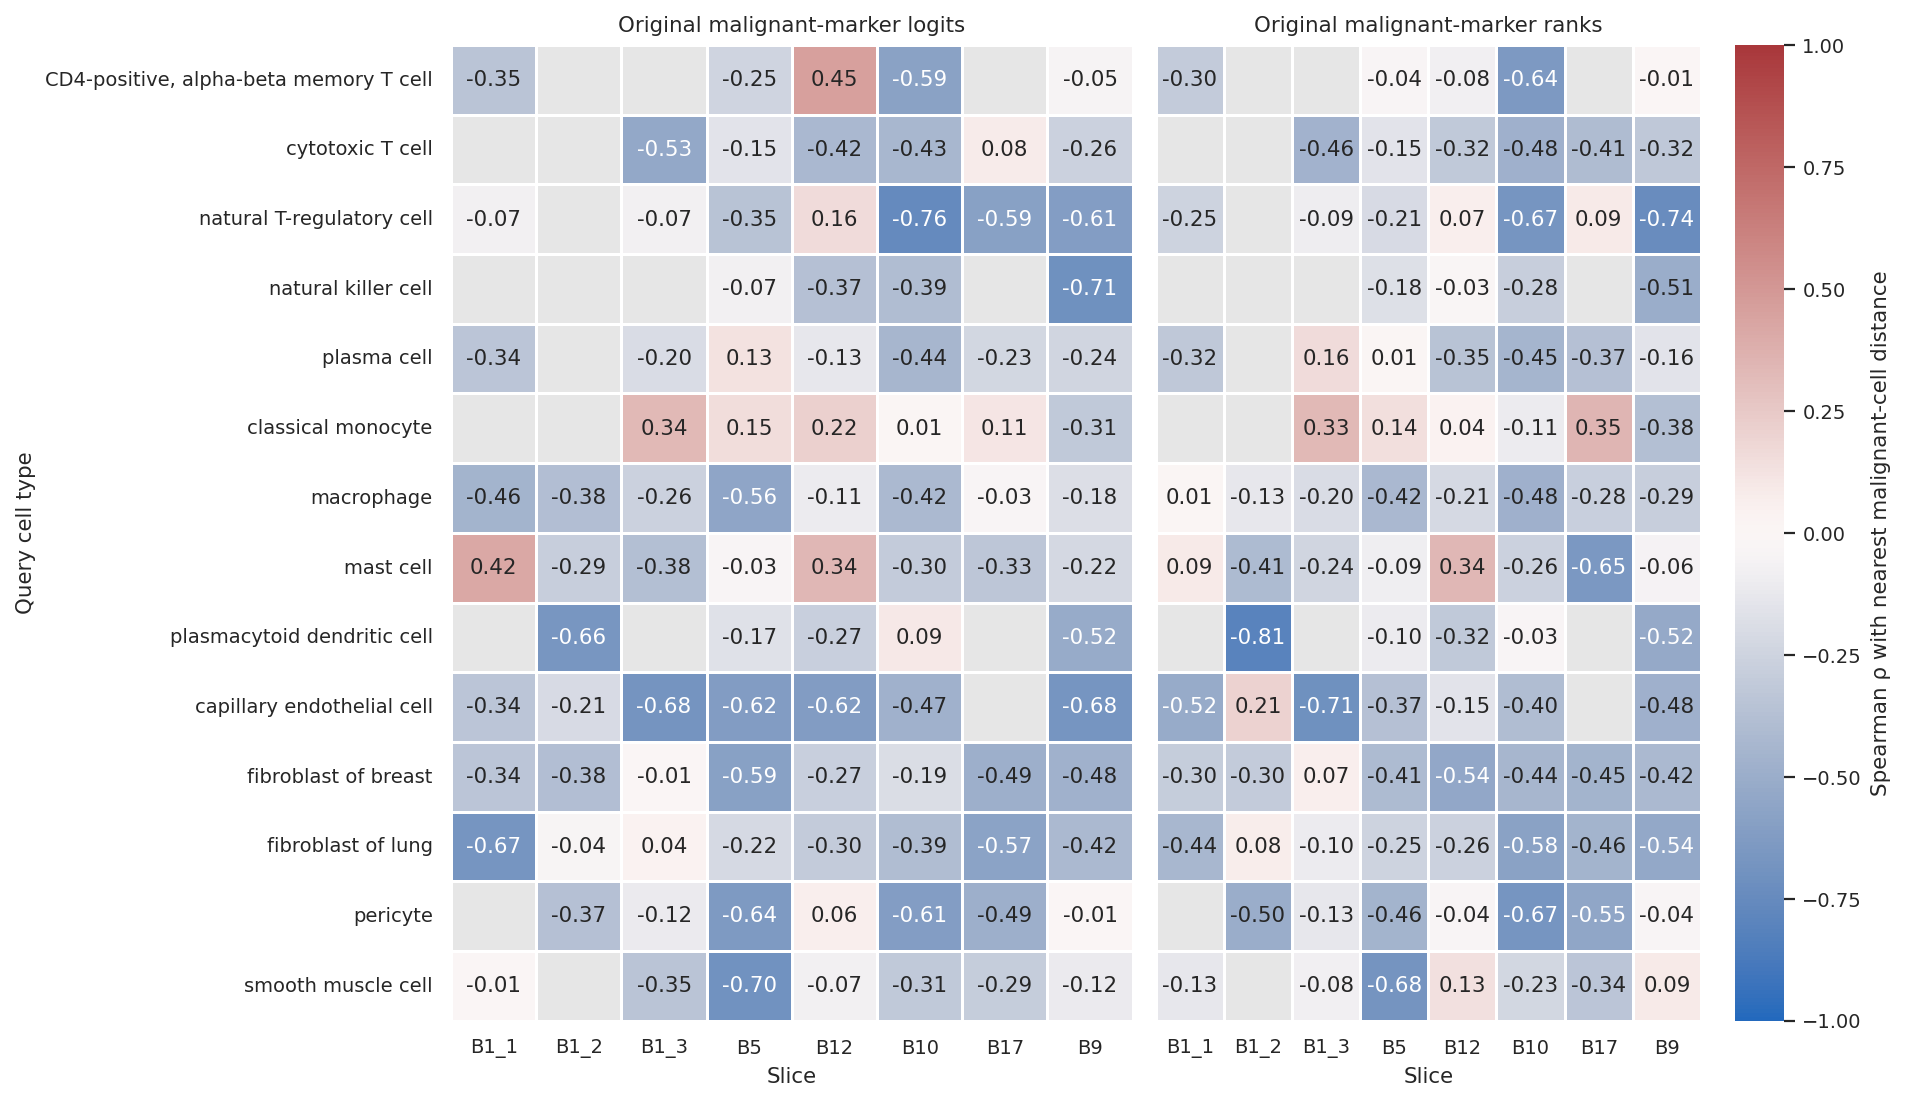

n_supported_slices  median_rho
query_cell_type                        metric                                                          
CD4-positive, alpha-beta memory T cell malignant_marker_logit                             5   -0.245455
                                       malignant_marker_rank_percentile                   5   -0.078788
                                       mean_expressed_gene_logit                          8   -0.055617
capillary endothelial cell             malignant_marker_logit                             7   -0.622078
                                       malignant_marker_rank_percentile                   7   -0.397918
                                       mean_expressed_gene_logit                          8   -0.133704
classical monocyte                     malignant_marker_logit                             6    0.131132
                                       malignant_marker_rank_percentile                   6    0.092876
                                       mean_expressed_gene_logit                          8    0.020690
cytotoxic T cell                       malignant_marker_logit                             6   -0.343202
                                       malignant_marker_rank_percentile                   6   -0.363627
                                       mean_expressed_gene_logit                          8   -0.088098
fibroblast of breast                   malignant_marker_logit                             8   -0.360440
                                       malignant_marker_rank_percentile                   8   -0.414081
                                       mean_expressed_gene_logit                          8   -0.037820
fibroblast of lung                     malignant_marker_logit                             8   -0.344639
                                       malignant_marker_rank_percentile                   8   -0.347950
                                       mean_expressed_gene_logit                          8   -0.065406
macrophage                             malignant_marker_logit                             8   -0.323435
                                       malignant_marker_rank_percentile                   8   -0.246000
                                       mean_expressed_gene_logit                          8    0.011123
mast cell                              malignant_marker_logit                             8   -0.254516
                                       malignant_marker_rank_percentile                   8   -0.164215
                                       mean_expressed_gene_logit                          8   -0.115684
natural T-regulatory cell              malignant_marker_logit                             7   -0.353846
                                       malignant_marker_rank_percentile                   7   -0.208791
                                       mean_expressed_gene_logit                          8    0.010456
natural killer cell                    malignant_marker_logit                             4   -0.379476
                                       malignant_marker_rank_percentile                   4   -0.232271
                                       mean_expressed_gene_logit                          8   -0.028699
pericyte                               malignant_marker_logit                             7   -0.375000
                                       malignant_marker_rank_percentile                   7   -0.455446
                                       mean_expressed_gene_logit                          8   -0.046051
plasma cell                            malignant_marker_logit                             7   -0.230769
                                       malignant_marker_rank_percentile                   7   -0.323529
                                       mean_expressed_gene_logit                          8    0.028699
plasmacytoid dendritic cell            malignant_marker_logit                             5   -0.274725
                 

In [11]:
fig,axes=plt.subplots(1,2,figsize=(12,7),sharey=True)
nonmalignant_types=[t for t in TYPE_ORDER if t!='malignant cell']
for ax,metric,title in zip(axes,['malignant_marker_logit','malignant_marker_rank_percentile'],
                          ['Original malignant-marker logits','Original malignant-marker ranks']):
    selected=distance_correlations.loc[distance_correlations.metric.eq(metric)]
    heat=selected.pivot(index='query_cell_type',columns='slice',values='spearman_rho').reindex(index=nonmalignant_types,columns=SLICE_ORDER).rename(columns=SLICE_LABELS)
    ax.set_facecolor('0.9')
    sns.heatmap(heat,mask=heat.isna(),cmap='vlag',center=0,vmin=-1,vmax=1,annot=True,fmt='.2f',linewidths=.5,
                ax=ax,cbar=(metric=='malignant_marker_rank_percentile'),cbar_kws={'label':'Spearman ρ with nearest malignant-cell distance'})
    ax.set(title=title,xlabel='Slice',ylabel='Query cell type' if metric=='malignant_marker_logit' else '')
fig.tight_layout();save_numbered(fig,'original_malignant_distance_correlations');plt.show()
display(distance_correlations.groupby(['query_cell_type','metric']).agg(n_supported_slices=('spearman_rho','count'),median_rho=('spearman_rho','median')))


### Predefined examples: actual query distance and original scores

Points are individual query cells colored by slice. Distances use a symmetric-log display with a 10-µm linear region so zeros and the full distance range remain visible. These scores are absolute original-context values, rather than changes from a swapped context. Only queries expressing at least one listed epithelial/malignant marker contribute; ranks additionally require ≥10 expressed genes.


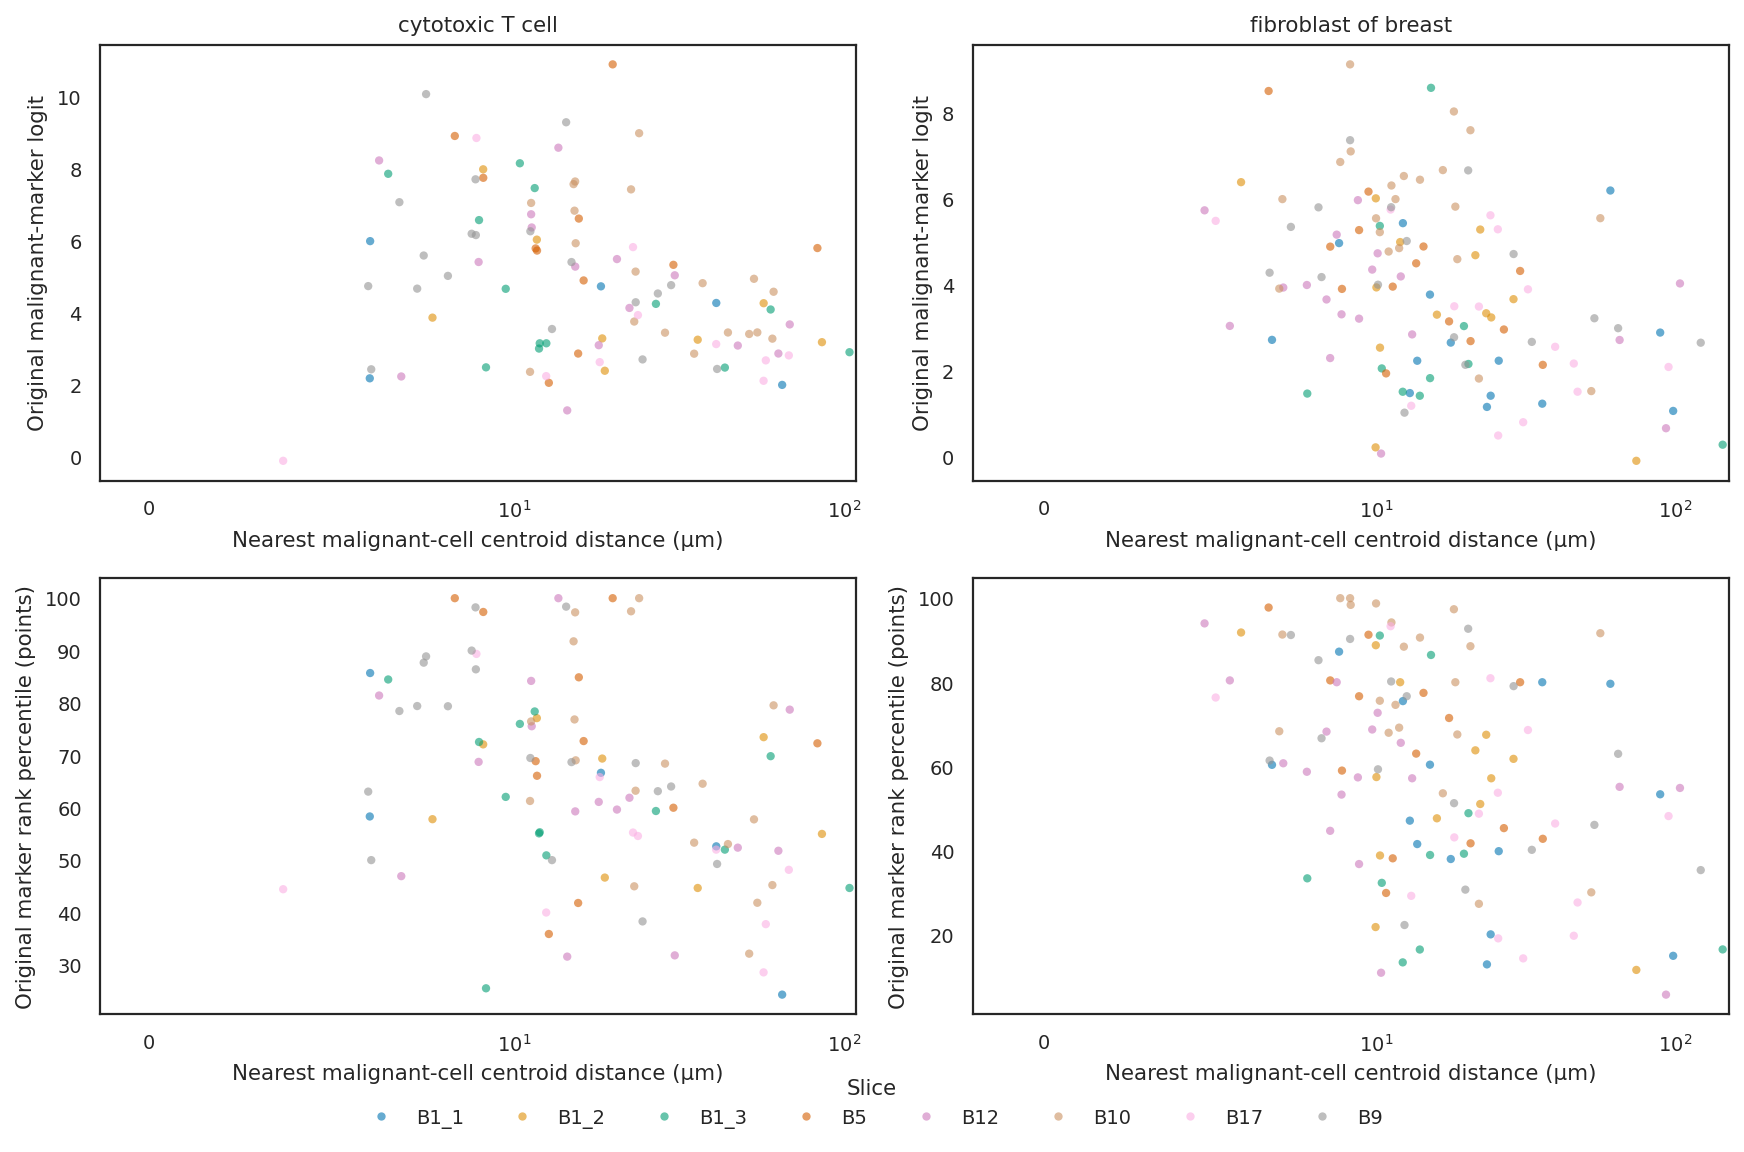

In [12]:
fig,axes=plt.subplots(2,2,figsize=(11,7),squeeze=False)
for col,(query_type,_) in enumerate(EXAMPLES):
    selected=distance_original.loc[distance_original.query_cell_type.eq(query_type)].copy()
    selected['malignant_marker_rank_percentile_points']=100*selected.malignant_marker_rank_percentile
    for row,metric,label in [(0,'malignant_marker_logit','Original malignant-marker logit'),
                             (1,'malignant_marker_rank_percentile_points','Original marker rank percentile (points)')]:
        ax=axes[row,col];data=selected.dropna(subset=[metric])
        if data.empty:
            ax.text(.5,.5,'Insufficient marker support',ha='center',va='center',transform=ax.transAxes)
        else:
            sns.scatterplot(data=data,x='query_distance_um',y=metric,hue='slice',hue_order=SLICE_ORDER,
                            palette=SLICE_PALETTE,s=14,alpha=.6,edgecolor='none',legend=(row==0 and col==0),ax=ax)
        ax.set_xscale('symlog',linthresh=10)
        ax.set(title=query_type if row==0 else '',xlabel='Nearest malignant-cell centroid distance (µm)',ylabel=label)
handles,labels=axes[0,0].get_legend_handles_labels()
if handles:
    axes[0,0].get_legend().remove()
    fig.legend(handles,[SLICE_LABELS.get(label,label) for label in labels],title='Slice',loc='lower center',ncol=8,bbox_to_anchor=(.5,-.03),frameon=False)
fig.tight_layout();save_numbered(fig,'original_malignant_distance_examples');plt.show()


### Swapped-context donor distance versus response

Curves first average contexts within each query and 25-µm distance bin, then average queries within a slice. At least five queries must support a slice/bin. Donors farther from malignant cells can differ in several neighboring cell types, so these curves do not isolate a direct effect of distance. Donor contexts at zero distance change do not necessarily reproduce the original neighborhood; unchanged-context duplicates are verified separately as (0, 0).


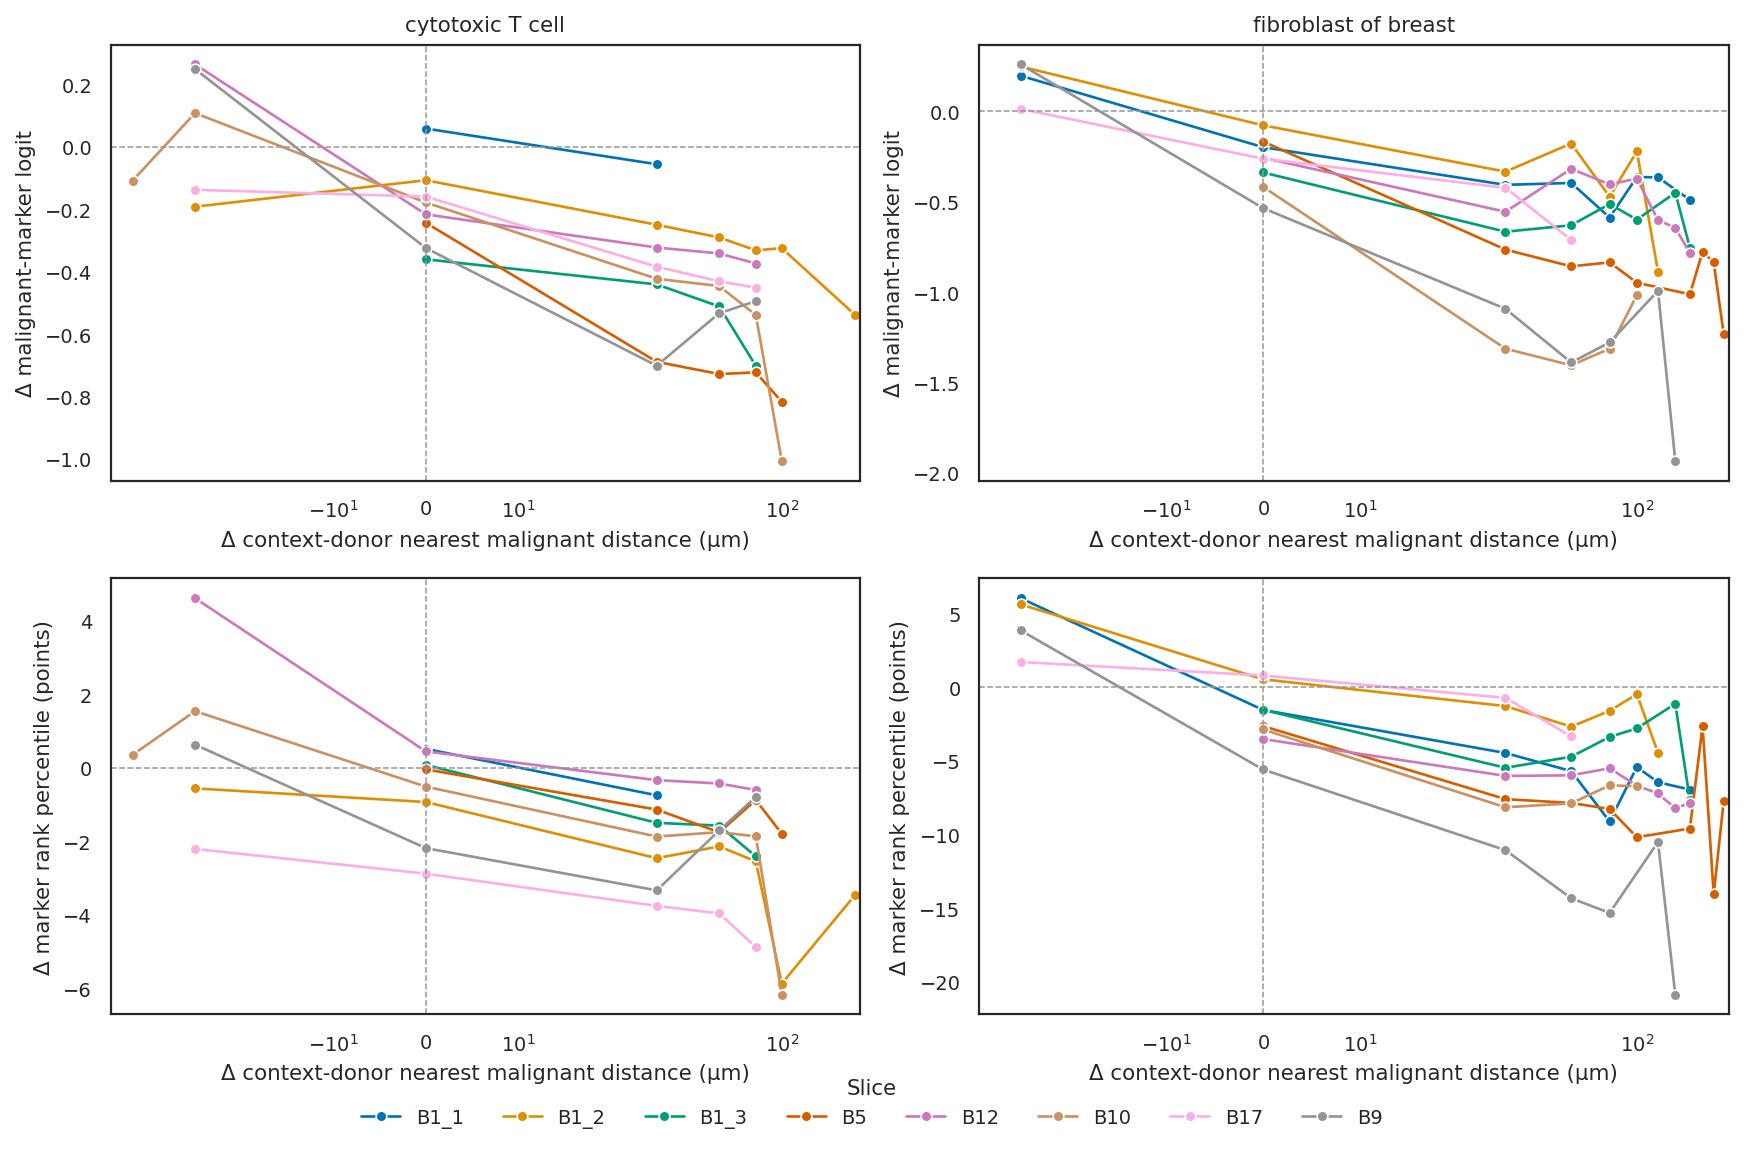

n_queries  median_within_query_rho
slice                                           query_cell_type      metric                                                          
GSM9509156_breast_breast_B17_B17_rctd_annotated cytotoxic T cell     delta_marker_logit                   10                -0.098109
                                                                     delta_marker_rank_percentile         10                 0.062544
                                                fibroblast of breast delta_marker_logit                   14                -0.327475
                                                                     delta_marker_rank_percentile         14                -0.245054
GSM9509162_breast_breast_B12_B12_rctd_annotated cytotoxic T cell     delta_marker_logit                   15                -0.080311
                                                                     delta_marker_rank_percentile         15                -0.182478
                                                fibroblast of breast delta_marker_logit                   18                -0.204004
                                                                     delta_marker_rank_percentile         18                -0.344583
GSM9509164_breast_breast_B10_B10_rctd_annotated cytotoxic T cell     delta_marker_logit                   19                -0.299221
                                                                     delta_marker_rank_percentile         19                -0.311451
                                                fibroblast of breast delta_marker_logit                   21                -0.579978
                                                                     delta_marker_rank_percentile         21                -0.456442
GSM9509166_breast_breast_B9_B9_rctd_annotated   cytotoxic T cell     delta_marker_logit                   19                -0.479867
                                                                     delta_marker_rank_percentile         19                -0.134067
                                                fibroblast of breast delta_marker_logit                   17                -0.452280
                                                                     delta_marker_rank_percentile         17                -0.413847
GSM9509171_breast_breast_B5_B5_rctd_annotated   cytotoxic T cell     delta_marker_logit                   11                -0.535039
                                                                     delta_marker_rank_percentile         11                -0.377397
                                                fibroblast of breast delta_marker_logit                   14                -0.604449
                                                                     delta_marker_rank_percentile         14                -0.532255
GSM9509172_breast_breast_B1_B1_1_rctd_annotated cytotoxic T cell     delta_marker_logit                    5                -0.292547
                                                                     delta_marker_rank_percentile          5                -0.302709
                                                fibroblast of breast delta_marker_logit                   14                -0.374416
                                                                     delta_marker_rank_percentile         14                -0.343138
GSM9509173_breast_breast_B1_B1_2_rctd_annotated cytotoxic T cell     delta_marker_logit                    8                -0.158621
                                                                     delta_marker_rank_percentile          8                -0.214455
                                                fibroblast of breast delta_marker_logit                   13                -0.201335
                                                                     delta_marker_rank_percentile         13                -0.231672
GSM9509174_breast_breast_B1_B1_3_rctd_annotated cytotoxic T cell     delta_mark

In [13]:
fig,axes=plt.subplots(2,2,figsize=(11,7),squeeze=False)
x_column='delta_context_source_distance_um' if DISTANCE_X_MODE=='delta' else 'context_source_distance_um'
x_label='Δ context-donor nearest malignant distance (µm)' if DISTANCE_X_MODE=='delta' else 'Context-donor nearest malignant distance (µm)'
for col,(query_type,_) in enumerate(EXAMPLES):
    selected=distance_contexts.loc[distance_contexts.query_cell_type.eq(query_type)&distance_contexts.context_kind.eq('representative')].copy()
    selected['distance_bin']=DISTANCE_BIN_WIDTH_UM*np.rint(selected[x_column]/DISTANCE_BIN_WIDTH_UM)
    selected['delta_marker_rank_percentile_points']=100*selected.delta_marker_rank_percentile
    for row,metric,label in [(0,'delta_marker_logit','Δ malignant-marker logit'),
                             (1,'delta_marker_rank_percentile_points','Δ marker rank percentile (points)')]:
        ax=axes[row,col]
        data=selected.dropna(subset=[metric])
        by_query=data.groupby(['slice','query_cell_id','distance_bin'])[metric].mean().rename('response').reset_index()
        by_slice=by_query.groupby(['slice','distance_bin']).agg(response=('response','mean'),n_queries=('query_cell_id','nunique')).reset_index()
        by_slice=by_slice.loc[by_slice.n_queries>=MIN_QUERIES_PER_DISTANCE_BIN]
        if not by_slice.empty:
            sns.lineplot(data=by_slice,x='distance_bin',y='response',hue='slice',hue_order=SLICE_ORDER,palette=SLICE_PALETTE,
                         marker='o',estimator=None,legend=(row==0 and col==0),ax=ax)
        else:
            ax.text(.5,.5,'Insufficient distance-bin support',ha='center',va='center',transform=ax.transAxes)
        ax.axhline(0,color='0.6',linestyle='--',linewidth=.7)
        if DISTANCE_X_MODE=='delta':ax.axvline(0,color='0.6',linestyle='--',linewidth=.7)
        ax.set_xscale('symlog',linthresh=DISTANCE_BIN_WIDTH_UM)
        ax.set(title=query_type if row==0 else '',xlabel=x_label,ylabel=label)
handles,labels=axes[0,0].get_legend_handles_labels()
if handles:
    axes[0,0].get_legend().remove()
    fig.legend(handles,[SLICE_LABELS.get(label,label) for label in labels],title='Slice',loc='lower center',ncol=8,bbox_to_anchor=(.5,-.03),frameon=False)
fig.tight_layout();save_numbered(fig,f'context_donor_malignant_distance_{DISTANCE_X_MODE}');plt.show()
display(distance_context_correlations.groupby(['slice','query_cell_type','metric']).agg(n_queries=('spearman_rho','count'),median_within_query_rho=('spearman_rho','median')))


## Are cells nearer malignant cells more context-responsive?

Here the x-axis is the **query cell's actual distance to the nearest annotated malignant centroid**, not the context donor's distance. The y-axis measures how strongly that query responds across substituted neighborhoods. This is different from comparing absolute original-context scores with proximity.

Primary measurements use an **identical context panel for all queries of the same type in the same slice**. The prespecified panel is reconstructed from donor IDs. When a query is itself one of the panel's donors, its original-context prediction fills that panel position; otherwise, extra original baselines and unchanged controls are excluded. Every query is explicitly checked to have the same donor IDs and ordering. No new inference is required.

- **All-gene logit SD:** average across expressed genes of each gene's SD across the common panel.
- **Malignant-marker logit SD:** SD across the panel of the mean expressed epithelial/malignant-marker logit score.
- **Pairwise rank distance:** mean of 1 − Spearman ρ over all pairs of panel contexts, restricted to the same expressed genes within a query (≥10 genes; average ranks for ties).

These measures do not subtract the original context, so variation in the original neighborhood does not determine responsiveness mechanically. They still depend on the query's expression profile, available expressed markers, and chosen context panel. Panels are matched within slice/type, not across types or slices. Malignant query cells remain excluded from distance associations because their self-inclusive distance is zero.


In [14]:
QUERY_RESPONSIVENESS = RUN/'summaries_query_distance_responsiveness'
if not (QUERY_RESPONSIVENESS/'complete.json').exists():
    raise FileNotFoundError(f'Query-distance responsiveness not available: {QUERY_RESPONSIVENESS}')
print(json.loads((QUERY_RESPONSIVENESS/'complete.json').read_text()))
query_distance_responses = pd.read_csv(QUERY_RESPONSIVENESS/'query_distance_responsiveness.csv')
query_distance_correlations = pd.read_csv(QUERY_RESPONSIVENESS/'distance_responsiveness_correlations.csv')
matched_panels = pd.read_csv(QUERY_RESPONSIVENESS/'matched_context_panels.csv')
display(matched_panels.drop(columns='donor_ids_json'))
PRIMARY_DISTANCE_RESPONSES = {
    'mean_gene_logit_sd':'All-gene logit SD',
    'malignant_marker_score_sd':'Malignant-marker logit SD',
    'mean_pairwise_rank_distance':'Pairwise gene-rank distance',
}


{'n_slices': 8, 'n_queries': 3600, 'context_panels': 'Identical donor IDs within each slice and query type, including original rows only when that donor belongs to the shared panel', 'primary': 'Baseline-independent SD across contexts and mean pairwise rank distance', 'sensitivity': 'Existing original-context-relative logit/rank changes', 'logit_epsilon': 1e-06, 'distance': 'Actual query centroid distance in micrometers, same annotated malignant reference as prior section'}


,slice,query_cell_type,n_panel_contexts,n_queries
0,GSM9509172_breast_breast_B1_B1_1_rctd_annotated,"CD4-positive, alpha-beta memory T cell",30,30
1,GSM9509172_breast_breast_B1_B1_1_rctd_annotated,capillary endothelial cell,30,30
2,GSM9509172_breast_breast_B1_B1_1_rctd_annotated,classical monocyte,30,30
3,GSM9509172_breast_breast_B1_B1_1_rctd_annotated,cytotoxic T cell,30,30
4,GSM9509172_breast_breast_B1_B1_1_rctd_annotated,fibroblast of breast,30,30
...,...,...,...,...
115,GSM9509166_breast_breast_B9_B9_rctd_annotated,natural killer cell,30,30
116,GSM9509166_breast_breast_B9_B9_rctd_annotated,pericyte,30,30
117,GSM9509166_breast_breast_B9_B9_rctd_annotated,plasma cell,30,30
118,GSM9509166_breast_breast_B9_B9_rctd_annotated,plasmacytoid dendritic cell,30,30


### Associations across cell types and slices

Tiles are within-slice/type correlations between actual query distance and responsiveness. **Negative values mean nearer cells tend to respond more strongly; positive values mean farther cells do.** Gray indicates insufficient support (fewer than ten queries or insufficient distance/response variation). Values are descriptive, without treating individual cells as independent biological replicates. A lack of association would not contradict the preceding donor-context distance response: the two analyses ask different questions.


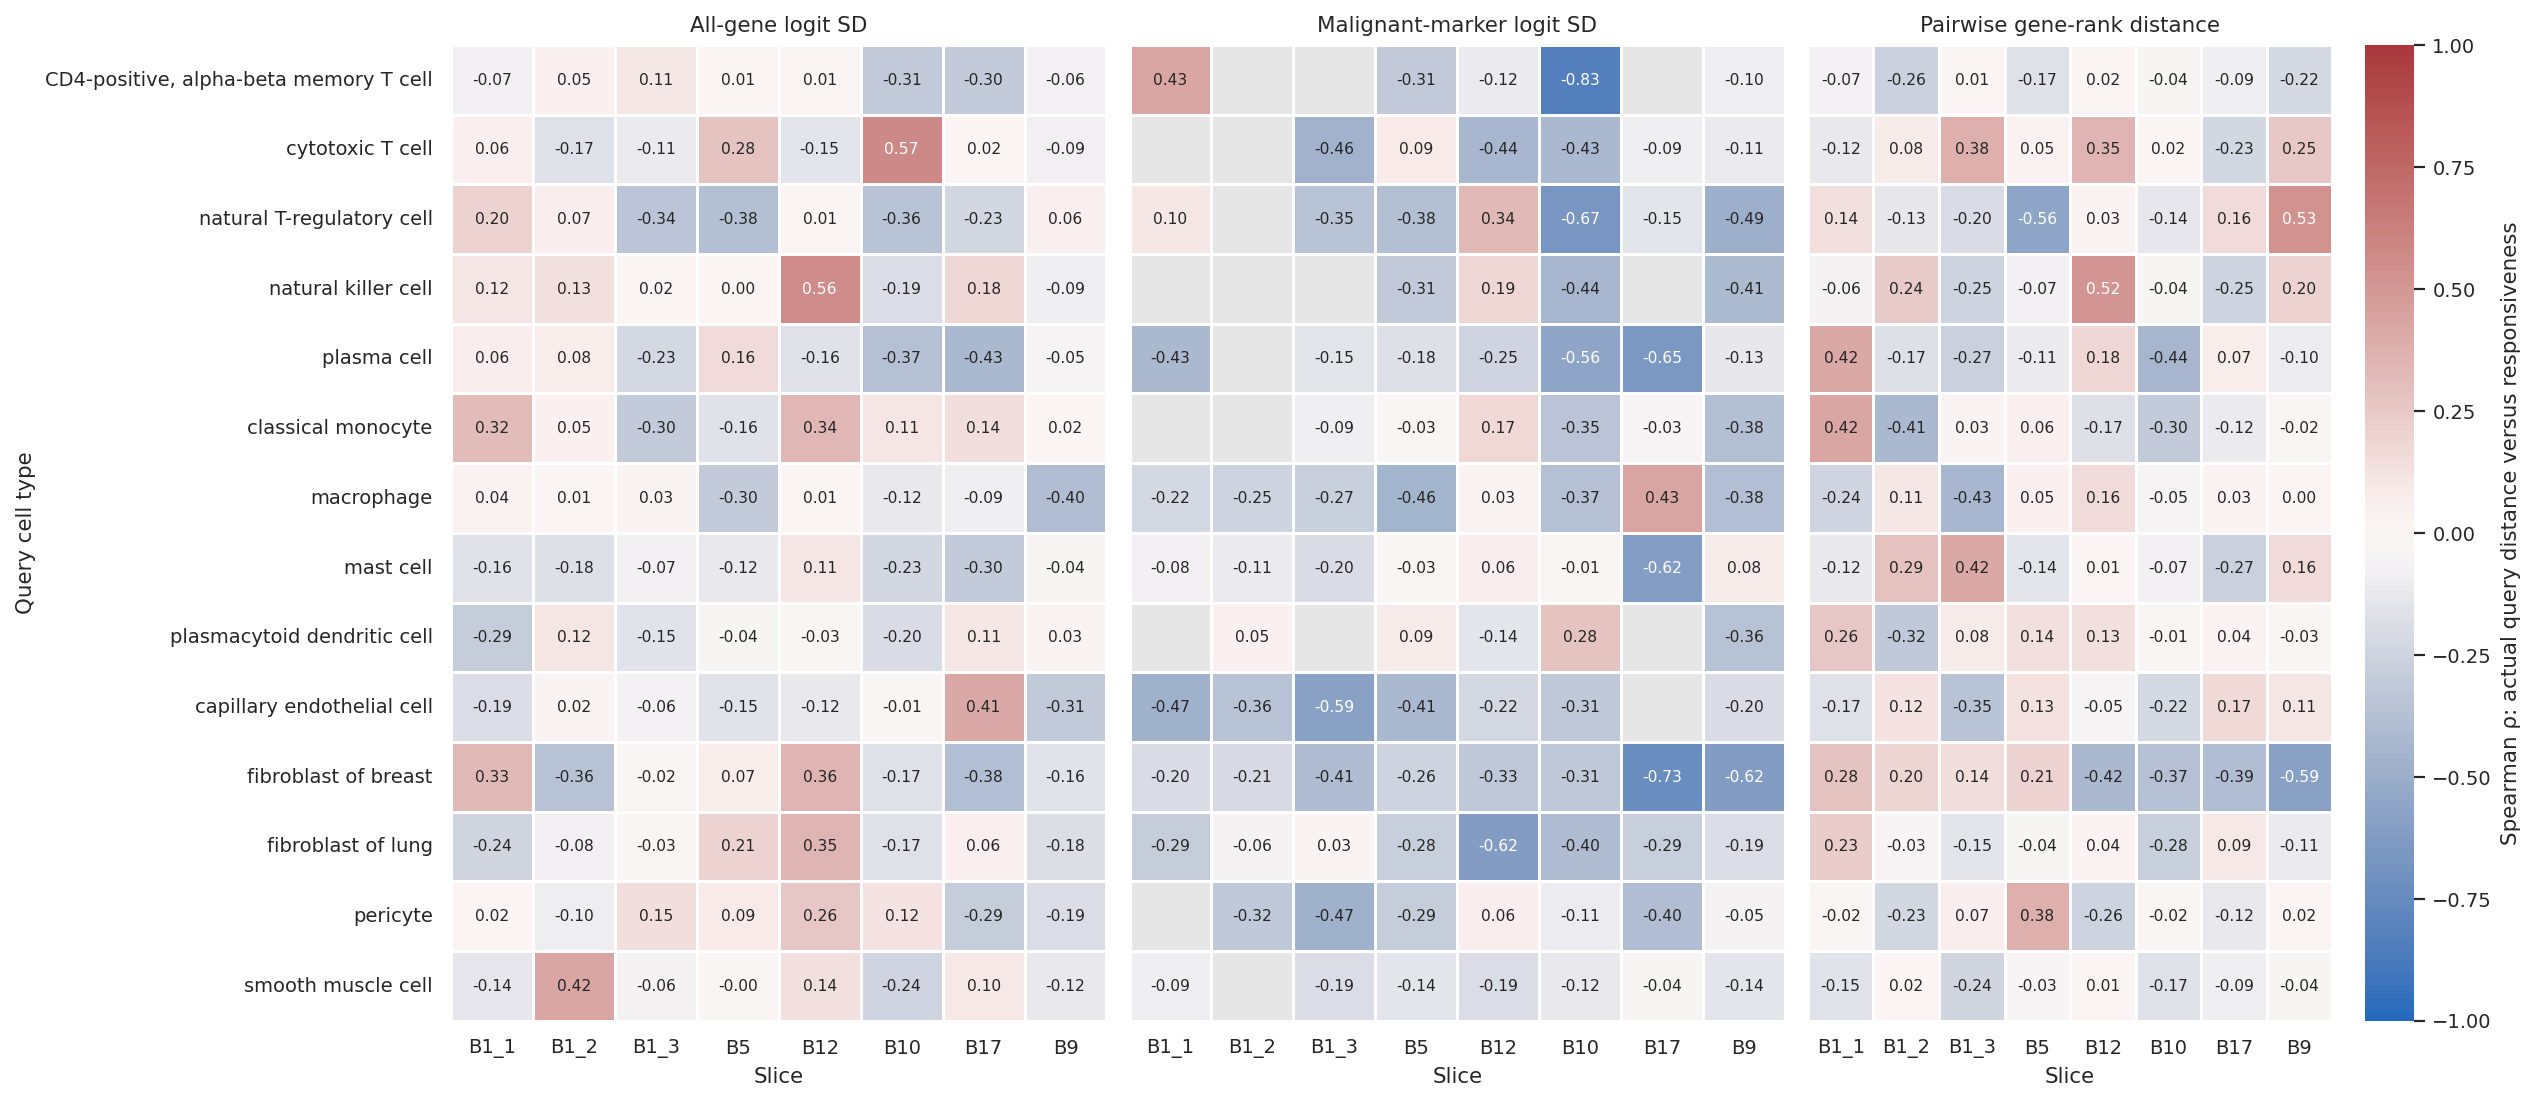

n_supported_slices  ...  n_negative_slices
query_cell_type                        metric                                           ...                   
CD4-positive, alpha-beta memory T cell malignant_marker_score_sd                     5  ...                  4
                                       mean_gene_logit_sd                            8  ...                  4
                                       mean_pairwise_rank_distance                   8  ...                  6
capillary endothelial cell             malignant_marker_score_sd                     7  ...                  7
                                       mean_gene_logit_sd                            8  ...                  6
                                       mean_pairwise_rank_distance                   8  ...                  4
classical monocyte                     malignant_marker_score_sd                     6  ...                  5
                                       mean_gene_logit_sd                            8  ...                  2
                                       mean_pairwise_rank_distance                   8  ...                  5
cytotoxic T cell                       malignant_marker_score_sd                     6  ...                  5
                                       mean_gene_logit_sd                            8  ...                  4
                                       mean_pairwise_rank_distance                   8  ...                  2
fibroblast of breast                   malignant_marker_score_sd                     8  ...                  8
                                       mean_gene_logit_sd                            8  ...                  5
                                       mean_pairwise_rank_distance                   8  ...                  4
fibroblast of lung                     malignant_marker_score_sd                     8  ...                  7
                                       mean_gene_logit_sd                            8  ...                  5
                                       mean_pairwise_rank_distance                   8  ...                  5
macrophage                             malignant_marker_score_sd                     8  ...                  6
                                       mean_gene_logit_sd                            8  ...                  4
                                       mean_pairwise_rank_distance                   8  ...                  3
malignant cell                         malignant_marker_score_sd                     0  ...                  0
                                       mean_gene_logit_sd                            0  ...                  0
                                       mean_pairwise_rank_distance                   0  ...                  0
mast cell                              malignant_marker_score_sd                     8  ...                  6
                                       mean_gene_logit_sd                            8  ...                  7
                                       mean_pairwise_rank_distance                   8  ...                  4
natural T-regulatory cell              malignant_marker_score_sd                     7  ...                  5
                                       mean_gene_logit_sd                            8  ...                  4
                                       mean_pairwise_rank_distance                   8  ...                  4
natural killer cell                    malignant_marker_score_sd                     4  ...                  3
                                       mean_gene_logit_sd                            8  ...                  2
                                       mean_pairwise_rank_distance                   8  ...                  5
pericyte                               malignant_marker_score_sd                     7  ...                  6
                                       mean_gene_logit_sd               

In [15]:
fig,axes=plt.subplots(1,3,figsize=(16,7),sharey=True)
for ax,(metric,title) in zip(axes,PRIMARY_DISTANCE_RESPONSES.items()):
    selected=query_distance_correlations.loc[query_distance_correlations.metric.eq(metric)]
    heat=selected.pivot(index='query_cell_type',columns='slice',values='spearman_rho').reindex(index=nonmalignant_types,columns=SLICE_ORDER).rename(columns=SLICE_LABELS)
    ax.set_facecolor('0.9')
    sns.heatmap(heat,mask=heat.isna(),cmap='vlag',center=0,vmin=-1,vmax=1,annot=True,fmt='.2f',linewidths=.5,
                annot_kws={'fontsize':7},ax=ax,cbar=(metric=='mean_pairwise_rank_distance'),
                cbar_kws={'label':'Spearman ρ: actual query distance versus responsiveness'})
    ax.set(title=title,xlabel='Slice',ylabel='Query cell type' if metric=='mean_gene_logit_sd' else '')
fig.tight_layout();save_numbered(fig,'query_distance_vs_context_responsiveness');plt.show()
display(query_distance_correlations.loc[query_distance_correlations.metric.isin(PRIMARY_DISTANCE_RESPONSES)].groupby(['query_cell_type','metric']).agg(
    n_supported_slices=('spearman_rho','count'),median_rho=('spearman_rho','median'),
    n_negative_slices=('spearman_rho',lambda x:int((x<0).sum()))))


### Predefined examples: actual query proximity versus response spread

Faint points are individual queries; colored curves show per-slice means in 25-µm query-distance bins with at least five supported queries. The full positive-distance range is retained on a symmetric-log x-axis. Marker responsiveness requires at least one expressed listed marker; pairwise ranks require ≥10 expressed genes. This is not a plot of absolute marker scores or original-context-relative changes.


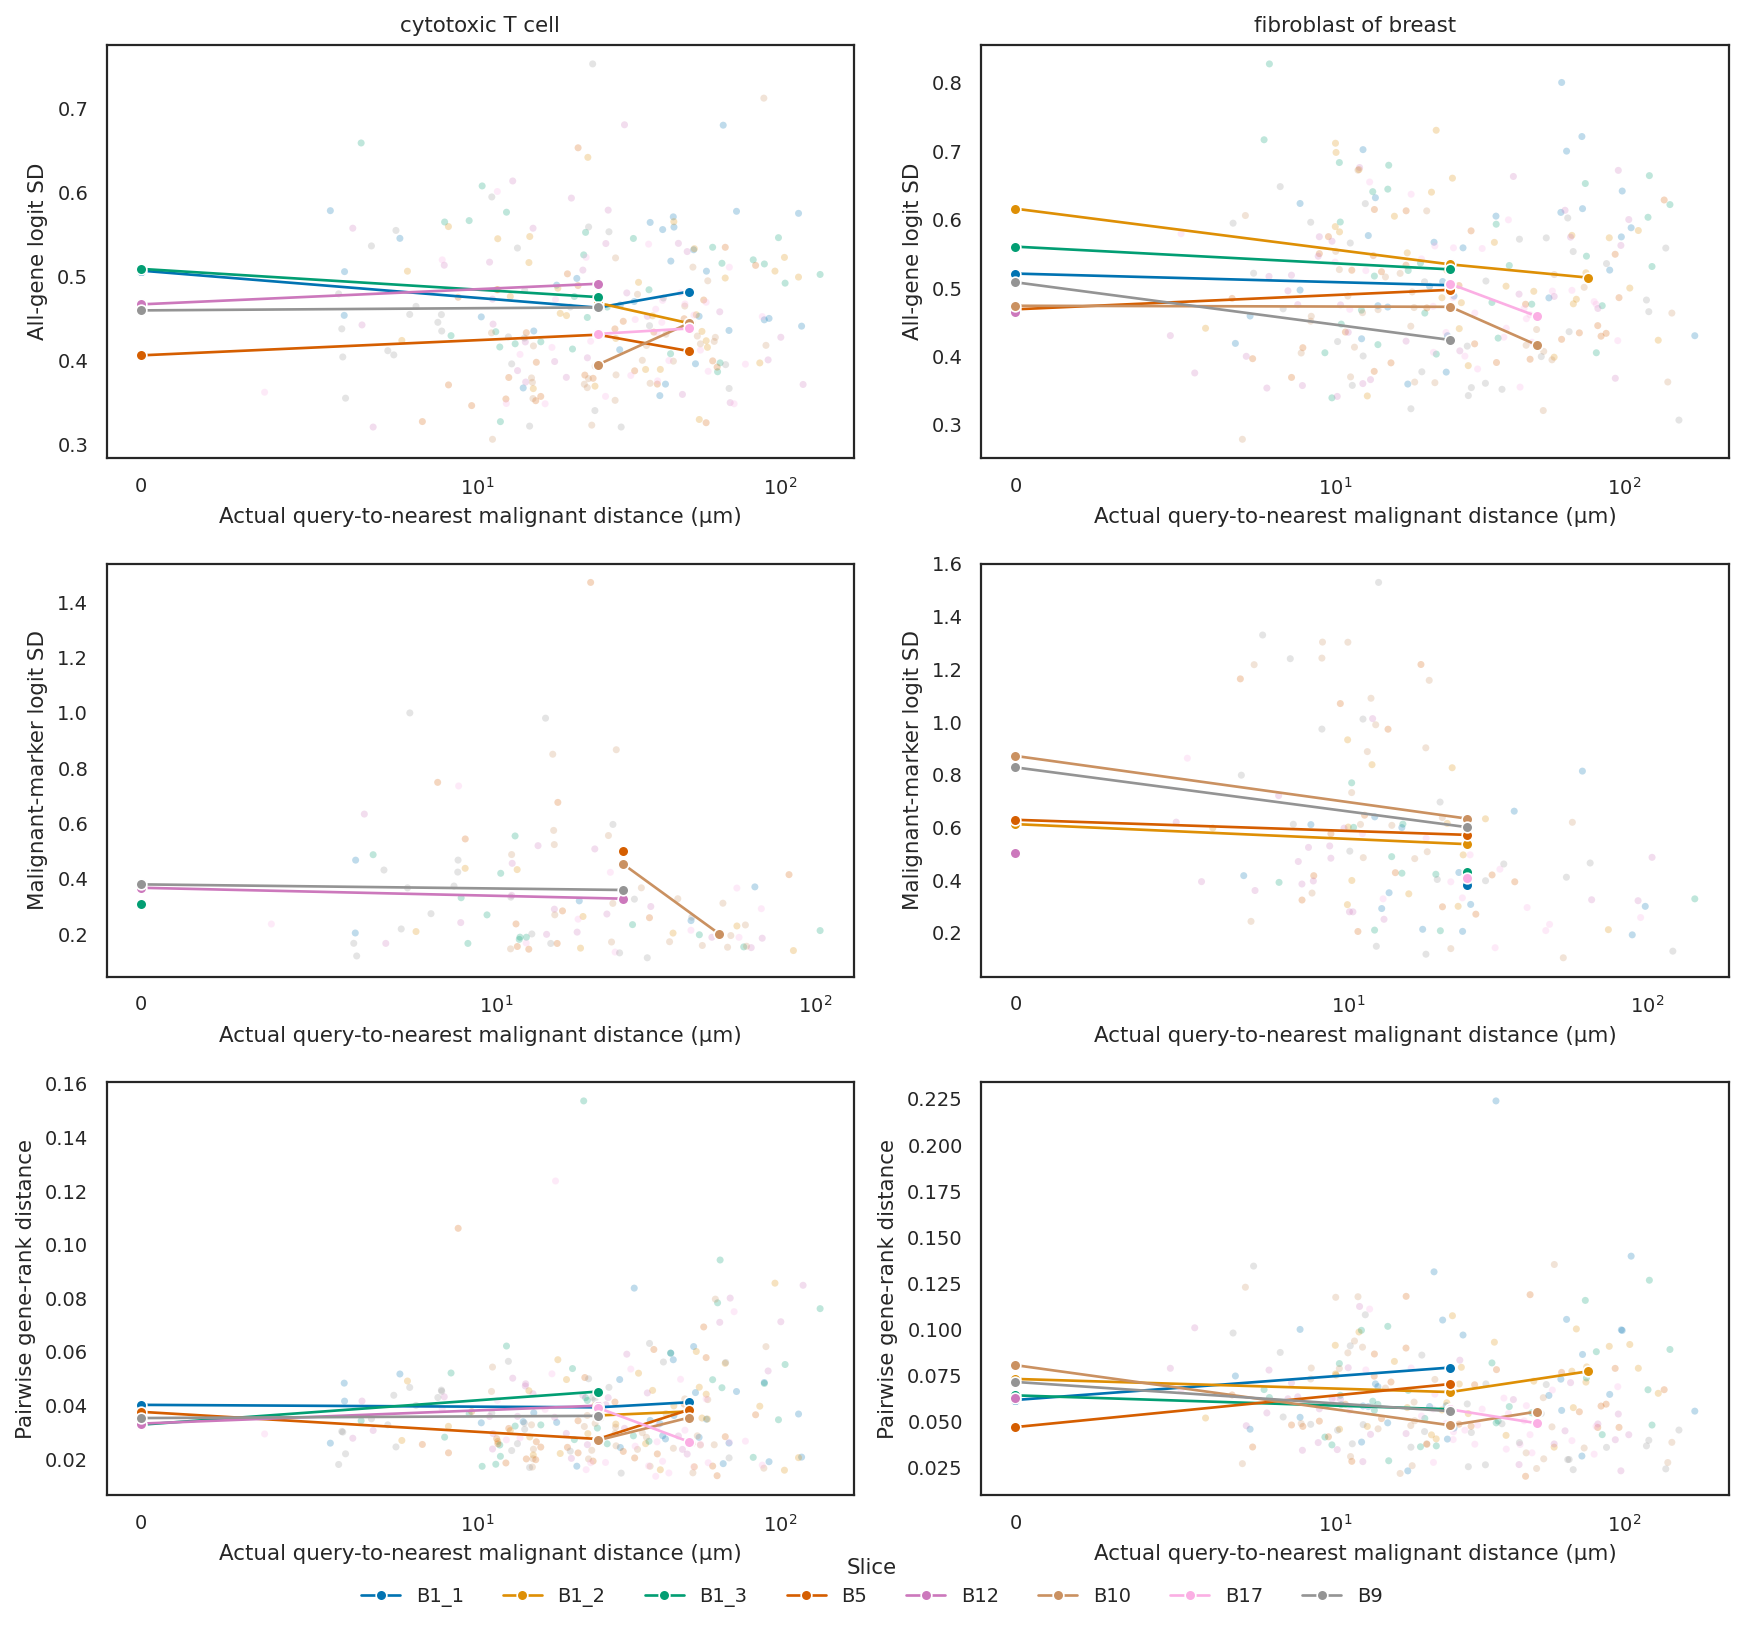

In [16]:
fig,axes=plt.subplots(3,2,figsize=(11,10),squeeze=False)
for col,(query_type,_) in enumerate(EXAMPLES):
    selected=query_distance_responses.loc[query_distance_responses.query_cell_type.eq(query_type)].copy()
    selected['distance_bin']=DISTANCE_BIN_WIDTH_UM*np.rint(selected.query_distance_um/DISTANCE_BIN_WIDTH_UM)
    for row,(metric,label) in enumerate(PRIMARY_DISTANCE_RESPONSES.items()):
        ax=axes[row,col];data=selected.dropna(subset=[metric])
        if not data.empty:
            sns.scatterplot(data=data,x='query_distance_um',y=metric,hue='slice',hue_order=SLICE_ORDER,
                            palette=SLICE_PALETTE,s=10,alpha=.25,edgecolor='none',legend=False,ax=ax)
            binned=data.groupby(['slice','distance_bin']).agg(response=(metric,'mean'),n_queries=('query_cell_id','nunique')).reset_index()
            binned=binned.loc[binned.n_queries>=MIN_QUERIES_PER_DISTANCE_BIN]
            if not binned.empty:
                sns.lineplot(data=binned,x='distance_bin',y='response',hue='slice',hue_order=SLICE_ORDER,
                             palette=SLICE_PALETTE,marker='o',estimator=None,legend=(row==0 and col==0),ax=ax)
        else:
            ax.text(.5,.5,'Insufficient support',ha='center',va='center',transform=ax.transAxes)
        ax.set_xscale('symlog',linthresh=10)
        ax.set(title=query_type if row==0 else '',xlabel='Actual query-to-nearest malignant distance (µm)',ylabel=label)
handles,labels=axes[0,0].get_legend_handles_labels()
if handles:
    axes[0,0].get_legend().remove()
    fig.legend(handles,[SLICE_LABELS.get(label,label) for label in labels],title='Slice',loc='lower center',ncol=8,bbox_to_anchor=(.5,-.02),frameon=False)
fig.tight_layout();save_numbered(fig,'query_distance_responsiveness_examples');plt.show()


### Sensitivity: change from the original neighborhood

The following table relates the earlier mean absolute logit change and original-relative rank distance to the query's actual proximity. These baseline-relative measures depend on how different the original neighborhood is from the sampled contexts. The matched-panel spread above is the primary analysis for this question. Signed malignant-marker context slopes are also retained in the exported query table for further inspection.


In [17]:
baseline_relative_metrics=['mean_absolute_delta_logit','mean_rank_distance']
display(query_distance_correlations.loc[query_distance_correlations.metric.isin(baseline_relative_metrics)].groupby(['query_cell_type','metric']).agg(
    n_supported_slices=('spearman_rho','count'),median_rho=('spearman_rho','median'),
    n_negative_slices=('spearman_rho',lambda x:int((x<0).sum()))))
display(query_distance_responses.loc[query_distance_responses.query_cell_type.isin([e[0] for e in EXAMPLES]),
    ['slice','query_cell_id','query_cell_type','query_distance_um','n_panel_contexts','n_expressed_genes',
     'n_expressed_malignant_markers',*PRIMARY_DISTANCE_RESPONSES,'mean_absolute_delta_logit','mean_rank_distance']])


n_supported_slices  ...  n_negative_slices
query_cell_type                        metric                                         ...                   
CD4-positive, alpha-beta memory T cell mean_absolute_delta_logit                   8  ...                  6
                                       mean_rank_distance                          8  ...                  7
capillary endothelial cell             mean_absolute_delta_logit                   8  ...                  7
                                       mean_rank_distance                          8  ...                  7
classical monocyte                     mean_absolute_delta_logit                   8  ...                  4
                                       mean_rank_distance                          8  ...                  6
cytotoxic T cell                       mean_absolute_delta_logit                   8  ...                  6
                                       mean_rank_distance                          8  ...                  4
fibroblast of breast                   mean_absolute_delta_logit                   8  ...                  5
                                       mean_rank_distance                          8  ...                  4
fibroblast of lung                     mean_absolute_delta_logit                   8  ...                  7
                                       mean_rank_distance                          8  ...                  6
macrophage                             mean_absolute_delta_logit                   8  ...                  6
                                       mean_rank_distance                          8  ...                  6
malignant cell                         mean_absolute_delta_logit                   0  ...                  0
                                       mean_rank_distance                          0  ...                  0
mast cell                              mean_absolute_delta_logit                   8  ...                  8
                                       mean_rank_distance                          8  ...                  6
natural T-regulatory cell              mean_absolute_delta_logit                   8  ...                  6
                                       mean_rank_distance                          8  ...                  4
natural killer cell                    mean_absolute_delta_logit                   8  ...                  5
                                       mean_rank_distance                          8  ...                  6
pericyte                               mean_absolute_delta_logit                   8  ...                  6
                                       mean_rank_distance                          8  ...                  6
plasma cell                            mean_absolute_delta_logit                   8  ...                  6
                                       mean_rank_distance                          8  ...                  7
plasmacytoid dendritic cell            mean_absolute_delta_logit                   8  ...                  6
                                       mean_rank_distance                          8  ...                  3
smooth muscle cell                     mean_absolute_delta_logit                   8  ...                  6
                                       mean_rank_distance                          8  ...                  6

[30 rows x 3 columns]

,slice,query_cell_id,query_cell_type,query_distance_um,n_panel_contexts,n_expressed_genes,n_expressed_malignant_markers,mean_gene_logit_sd,malignant_marker_score_sd,mean_pairwise_rank_distance,mean_absolute_delta_logit,mean_rank_distance
90,GSM9509172_breast_breast_B1_B1_1_rctd_annotated,GSM9509172_breast_breast_B1_B1_1:aangafab-1,cytotoxic T cell,40.848230,30,58,1,0.555691,0.248358,0.028674,0.610324,0.025291
91,GSM9509172_breast_breast_B1_B1_1_rctd_annotated,GSM9509172_breast_breast_B1_B1_1:bddnhobc-1,cytotoxic T cell,14.162454,30,51,0,0.367299,NaN,0.033928,0.365519,0.022127
92,GSM9509172_breast_breast_B1_B1_1_rctd_annotated,GSM9509172_breast_breast_B1_B1_1:bgkibhlb-1,cytotoxic T cell,53.868372,30,40,0,0.452532,NaN,0.028076,0.559959,0.036723
93,GSM9509172_breast_breast_B1_B1_1_rctd_annotated,GSM9509172_breast_breast_B1_B1_1:dapggapi-1,cytotoxic T cell,117.345394,30,47,0,0.440810,NaN,0.020706,0.439122,0.014647
94,GSM9509172_breast_breast_B1_B1_1_rctd_annotated,GSM9509172_breast_breast_B1_B1_1:dnbicgfo-1,cytotoxic T cell,37.147677,30,44,0,0.564174,NaN,0.034388,0.551653,0.025055
...,...,...,...,...,...,...,...,...,...,...,...,...
3295,GSM9509166_breast_breast_B9_B9_rctd_annotated,GSM9509166_breast_breast_B9_B9:lphpnomm-1,fibroblast of breast,51.667877,30,41,0,0.399725,NaN,0.054290,0.485118,0.063217
3296,GSM9509166_breast_breast_B9_B9_rctd_annotated,GSM9509166_breast_breast_B9_B9:maamheep-1,fibroblast of breast,8.270612,30,62,2,0.648131,1.239755,0.087460,0.825881,0.102655
3297,GSM9509166_breast_breast_B9_B9_rctd_annotated,GSM9509166_breast_breast_B9_B9:nhebjoca-1,fibroblast of breast,6.799361,30,67,2,0.594668,0.797563,0.097981,0.775532,0.099983
3298,GSM9509166_breast_breast_B9_B9_rctd_annotated,GSM9509166_breast_breast_B9_B9:nhfidcim-1,fibroblast of breast,12.674443,30,91,2,0.623262,1.529330,0.107872,0.770235,0.107943


## Focused panel: epithelial-marker context sensitivity near malignant cells

**Primary example: breast fibroblasts.** The left panel relates actual query-to-malignant-cell distance to the SD of the mean expressed epithelial-marker logit score across the same 30 contexts within each slice/type. Faint points are individual queries. Colored lines connect within-slice medians in prespecified distance bins (0–10, 10–25, 25–50, 50–100, 100–200, and ≥200 µm), retaining bins with ≥3 marker-supported queries; plotted x positions are the actual mean query distances in those bins. All individual queries remain visible even when their bin is too small for a line.

The right panel shows one within-slice Spearman correlation per section, using every marker-supported query rather than the binned values. Negative correlations mean nearby cells have greater context sensitivity. The B1 replicate rows are shaded together to make their relationship explicit. No pooled significance test treats sections as independent donors. The dotted line is the descriptive median section correlation.

This focused plot uses existing data; it does not expand query sampling or add new model inference. Marker sets remain provisional epithelial-associated genes. The figure establishes an association, rather than marker specificity against matched control genes or correction accuracy.


In [18]:
FOCUSED_QUERY_TYPE = 'fibroblast of breast'  # Optional alternative: 'cytotoxic T cell'.
FOCUSED_METRIC = 'malignant_marker_score_sd'
FOCUSED_DISTANCE_EDGES_UM = [0,10,25,50,100,200,np.inf]
FOCUSED_MIN_QUERIES_PER_BIN = 3
focused_cells = query_distance_responses.loc[
    query_distance_responses.query_cell_type.eq(FOCUSED_QUERY_TYPE)
].dropna(subset=['query_distance_um', FOCUSED_METRIC]).copy()
if focused_cells.empty:
    raise ValueError(f'No marker-supported queries for {FOCUSED_QUERY_TYPE}')
focused_cells['distance_bin'] = pd.cut(focused_cells.query_distance_um,
    FOCUSED_DISTANCE_EDGES_UM, right=False, include_lowest=True)
focused_bins = focused_cells.groupby(['slice','distance_bin'], observed=True).agg(
    mean_distance_um=('query_distance_um','mean'),
    median_responsiveness=(FOCUSED_METRIC,'median'),
    n_queries=('query_cell_id','nunique')).reset_index()
focused_bins = focused_bins.loc[focused_bins.n_queries >= FOCUSED_MIN_QUERIES_PER_BIN].copy()
focused_correlations = query_distance_correlations.loc[
    query_distance_correlations.query_cell_type.eq(FOCUSED_QUERY_TYPE)
    & query_distance_correlations.metric.eq(FOCUSED_METRIC)
].set_index('slice').reindex(SLICE_ORDER).reset_index()
focused_correlations['slice_label'] = focused_correlations['slice'].map(SLICE_LABELS)
focused_valid = focused_correlations.loc[focused_correlations.status.eq('ok')].copy()
focused_median_rho = focused_valid.spearman_rho.median()
focused_negative = int(focused_valid.spearman_rho.lt(0).sum())
display(focused_correlations[['slice_label','n_queries','spearman_rho','status']])


,slice_label,n_queries,spearman_rho,status
0,B1_1,14,-0.200000,ok
1,B1_2,13,-0.208791,ok
2,B1_3,10,-0.406061,ok
3,B5,14,-0.257143,ok
4,B12,18,-0.325077,ok
5,B10,21,-0.314286,ok
6,B17,14,-0.731868,ok
7,B9,17,-0.625000,ok


Focused panel exports: /home/jwinchel/Syndri/context_analysis/results/all_type_responsiveness_selected_20261018_150658/figures_logits/focused_fibroblast_of_breast_distance_1


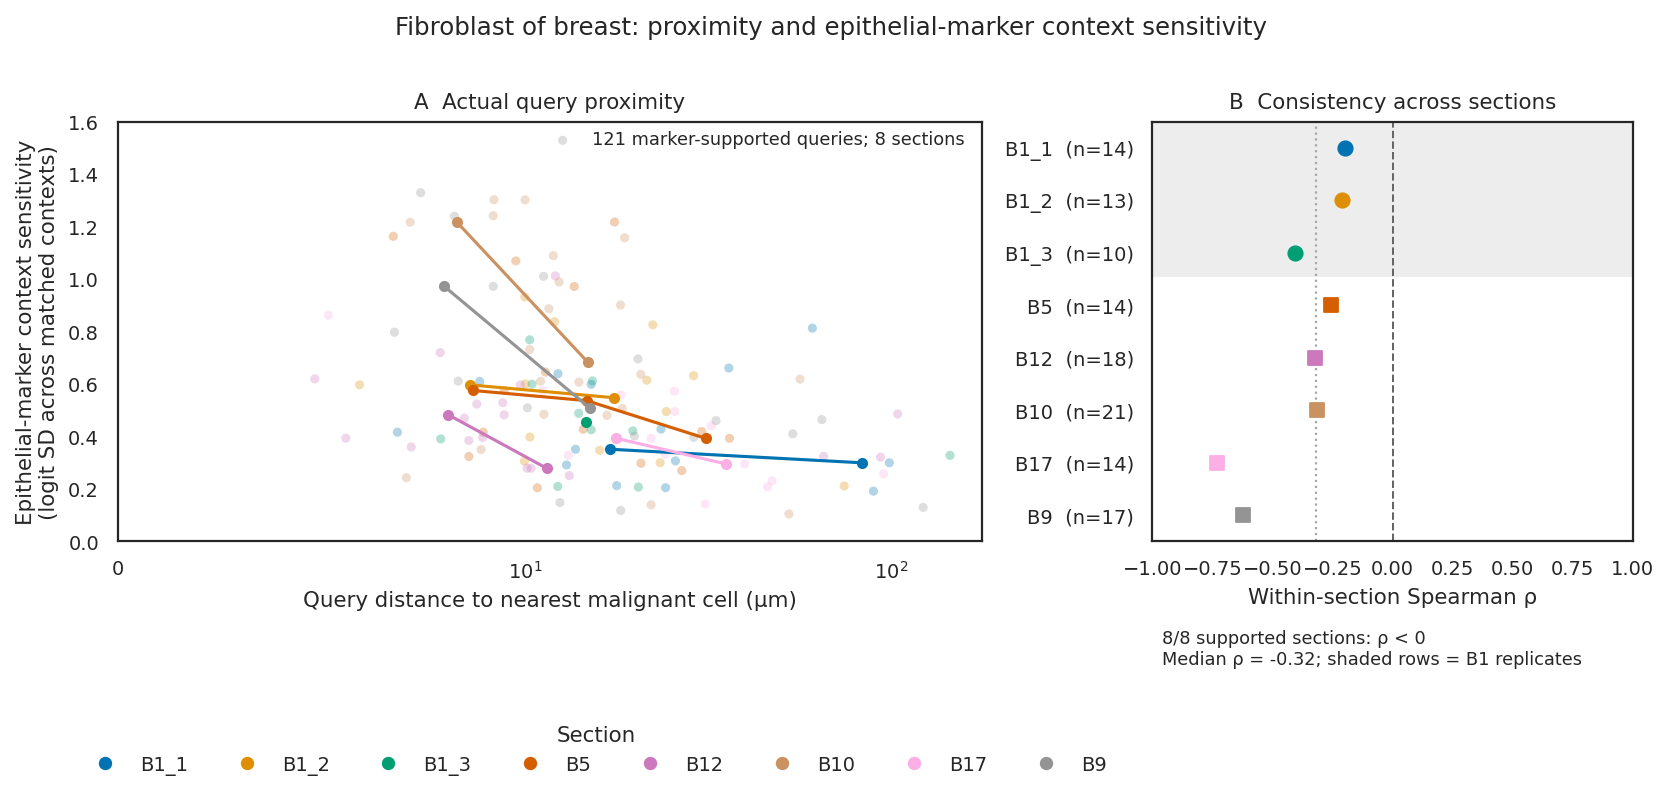

In [19]:
fig, (ax_curve, ax_rho) = plt.subplots(1,2,figsize=(10.5,4.3),
    gridspec_kw={'width_ratios':[1.8,1.0]})
for slice_id in SLICE_ORDER:
    current=focused_cells.loc[focused_cells['slice'].eq(slice_id)]
    if current.empty:
        continue
    color=SLICE_PALETTE[slice_id]
    ax_curve.scatter(current.query_distance_um,current[FOCUSED_METRIC],
                     color=color,s=17,alpha=.3,edgecolors='none',zorder=1)
    line=focused_bins.loc[focused_bins['slice'].eq(slice_id)].sort_values('mean_distance_um')
    if not line.empty:
        ax_curve.plot(line.mean_distance_um,line.median_responsiveness,color=color,
                      marker='o',markersize=4,linewidth=1.4,zorder=2)
ax_curve.set_xscale('symlog',linthresh=10)
ax_curve.set_xlim(left=0)
ax_curve.set_ylim(bottom=0)
ax_curve.set(xlabel='Query distance to nearest malignant cell (µm)',
             ylabel='Epithelial-marker context sensitivity\n(logit SD across matched contexts)',
             title='A  Actual query proximity')
ax_curve.text(.98,.98,f'{len(focused_cells)} marker-supported queries; '
              f'{focused_cells["slice"].nunique()} sections',
              ha='right',va='top',transform=ax_curve.transAxes,fontsize=8)
# Explicitly group related B1 sections while retaining each section's estimate.
replicate_positions=[i for i,s in enumerate(SLICE_ORDER) if SLICE_LABELS[s].startswith('B1_')]
if replicate_positions:
    ax_rho.axhspan(min(replicate_positions)-.45,max(replicate_positions)+.45,
                   color='0.93',zorder=0)
ax_rho.axvline(0,color='0.4',linestyle='--',linewidth=.9,zorder=1)
if pd.notna(focused_median_rho):
    ax_rho.axvline(focused_median_rho,color='0.65',linestyle=':',linewidth=1,zorder=1)
for position,slice_id in enumerate(SLICE_ORDER):
    row=focused_correlations.loc[focused_correlations['slice'].eq(slice_id)].iloc[0]
    if row.status=='ok' and pd.notna(row.spearman_rho):
        ax_rho.scatter(row.spearman_rho,position,color=SLICE_PALETTE[slice_id],s=42,
                       marker='o' if position in replicate_positions else 's',zorder=3)
    else:
        ax_rho.text(.02,position,'Insufficient support',ha='left',va='center',fontsize=7)
labels=[f'{SLICE_LABELS[s]}  (n={int(focused_correlations.loc[focused_correlations["slice"].eq(s),"n_queries"].iloc[0])})'
        for s in SLICE_ORDER]
ax_rho.set_yticks(range(len(SLICE_ORDER)),labels)
ax_rho.set_ylim(len(SLICE_ORDER)-.5,-.5)
ax_rho.set_xlim(-1,1)
ax_rho.set(xlabel='Within-section Spearman ρ',ylabel='',title='B  Consistency across sections')
ax_rho.text(.02,-.21,f'{focused_negative}/{len(focused_valid)} supported sections: ρ < 0\n'
             f'Median ρ = {focused_median_rho:.2f}; shaded rows = B1 replicates',
             transform=ax_rho.transAxes,ha='left',va='top',fontsize=8)
fig.suptitle(f'{FOCUSED_QUERY_TYPE.capitalize()}: proximity and epithelial-marker context sensitivity',
             fontsize=11,y=1.01)
handles=[plt.Line2D([0],[0],marker='o',linestyle='',markersize=5,color=SLICE_PALETTE[s],label=SLICE_LABELS[s])
         for s in SLICE_ORDER if s in set(focused_cells['slice'])]
fig.legend(handles=handles,title='Section',loc='lower center',ncol=8,
           bbox_to_anchor=(.36,-.12),frameon=False)
fig.tight_layout()
# Export the exact cells, bin summaries, and correlations alongside the figure.
focused_tag=FOCUSED_QUERY_TYPE.replace(' ','_')
export_index=1
while any((FIGURES/f'focused_{focused_tag}_distance_{export_index}{suffix}').exists()
          for suffix in ['.pdf','.png','_cells.csv','_bins.csv','_correlations.csv']):
    export_index+=1
focused_stem=FIGURES/f'focused_{focused_tag}_distance_{export_index}'
fig.savefig(focused_stem.with_suffix('.pdf'),bbox_inches='tight')
fig.savefig(focused_stem.with_suffix('.png'),dpi=300,bbox_inches='tight')
focused_cells.to_csv(str(focused_stem)+'_cells.csv',index=False)
focused_bins.to_csv(str(focused_stem)+'_bins.csv',index=False)
focused_correlations.to_csv(str(focused_stem)+'_correlations.csv',index=False)
plt.show()
print('Focused panel exports:',focused_stem)


In [20]:
focused_caption = (
    f'Context sensitivity of expressed epithelial-associated marker scores in {FOCUSED_QUERY_TYPE} query cells '
    f'was negatively associated with query distance to the nearest annotated malignant-cell centroid '
    f'in {focused_negative} of {len(focused_valid)} supported sections '
    f'(median within-section Spearman ρ = {focused_median_rho:.2f}). '
    'Sensitivity is the SD of the mean marker logit across the same 30 observed context donors '
    'within each section and query type. The B1 sections are related replicates; '
    'section-level correlations are descriptive, without an independence-based pooled significance test.'
)
print(focused_caption)


Context sensitivity of expressed epithelial-associated marker scores in fibroblast of breast query cells was negatively associated with query distance to the nearest annotated malignant-cell centroid in 8 of 8 supported sections (median within-section Spearman ρ = -0.32). Sensitivity is the SD of the mean marker logit across the same 30 observed context donors within each section and query type. The B1 sections are related replicates; section-level correlations are descriptive, without an independence-based pooled significance test.
